this is the analysis for the assessment 2 in MIS140 unit (Introduction to Machine Learning for Business Analysis)

#Import Libaries

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
import itertools


#Mount Google Drive to Colab

In [6]:
#from google.colab import drive
#drive.mount('/content/drive')

#Load Data

In [7]:
file_path = '/content/London Bike Sharing Dataset.csv'
df = pd.read_csv(file_path)

#Inspect Data

In [8]:
df

,timestamp,hour,day,month,year,is_holiday,is_weekend,season,t1,t2,hum,wind_speed,weather_code,cnt
0,2015-01-04 00:00:00,0,4,1,2015,0.0,1.0,Winter,3.0,2.0,93.0,6.0,3.0,182.0
1,2015-01-04 01:00:00,1,4,1,2015,0.0,1.0,Winter,3.0,2.5,93.0,5.0,1.0,138.0
2,2015-01-04 02:00:00,2,4,1,2015,0.0,1.0,Winter,2.5,2.5,96.5,0.0,1.0,134.0
3,2015-01-04 03:00:00,3,4,1,2015,0.0,1.0,Winter,2.0,2.0,100.0,0.0,1.0,72.0
4,2015-01-04 04:00:00,4,4,1,2015,0.0,1.0,Winter,2.0,0.0,93.0,6.5,1.0,47.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14448,2016-08-31 19:00:00,19,31,8,2016,0.0,0.0,Summer,22.0,22.0,65.0,21.5,2.0,2750.0
14449,2016-08-31 20:00:00,20,31,8,2016,0.0,0.0,Summer,21.0,21.0,69.0,23.0,2.0,1515.0
14450,2016-08-31 21:00:00,21,31,8,2016,0.0,0.0,Summer,20.0,20.0,71.0,19.0,2.0,1134.0
14451,2016-08-31 22:00:00,22,31,8,2016,0.0,0.0,Summer,19.0,19.0,64.0,19.5,1.0,853.0


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14453 entries, 0 to 14452
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   timestamp     14453 non-null  object 
 1   hour          14453 non-null  int64  
 2   day           14453 non-null  int64  
 3   month         14453 non-null  int64  
 4   year          14453 non-null  int64  
 5   is_holiday    14453 non-null  float64
 6   is_weekend    14453 non-null  float64
 7   season        14311 non-null  object 
 8   t1            14308 non-null  float64
 9   t2            14308 non-null  float64
 10  hum           14308 non-null  float64
 11  wind_speed    14308 non-null  float64
 12  weather_code  14453 non-null  float64
 13  cnt           14309 non-null  object 
dtypes: float64(7), int64(4), object(3)
memory usage: 1.5+ MB


In [10]:
# convert the column timestamp into early morning, morning, afternoon and evening
def categorize_time(timestamp):
    hour = timestamp.hour
    if 0 <= hour < 6:
        return 'Early Morning'
    elif 6 <= hour < 12:
        return 'Morning'
    elif 12 <= hour < 18:
        return 'Afternoon'
    else:
        return 'Evening'

# Convert Timestamp to datetime objects, specifying the format
#The errors='coerce' argument handles any parsing errors by setting them to NaT (Not a Time)
df['timestamp'] = pd.to_datetime(df['timestamp'], errors='coerce')

# Extract hour from Timestamp
df['Hour'] = df['timestamp'].dt.hour

if 'timestamp' in df.columns:
  df['TimeOfDay'] = df['timestamp'].dt.time.apply(categorize_time)
else:
  print("Warning: 'timestamp' column not found in the DataFrame.  Please check your column name.")
  # Or handle the missing column appropriately for your needs

In [11]:
#change timestamp to datetimes
#change cnt to int64
# replace 'sprng' to 'spring' in the season column

#Clean Data

In [12]:
#change timestamp data type from Object to datetimes
df['timestamp'] = pd.to_datetime(df['timestamp'])

In [13]:
# change cnt data type from object to float or int64
df['cnt'] = pd.to_numeric(df['cnt'], errors='coerce')

In [14]:
# Replace sprng to spring
df['season'] = df['season'].replace('sprng','Spring')

In [15]:
df.describe()

,timestamp,hour,day,month,year,is_holiday,is_weekend,t1,t2,hum,wind_speed,weather_code,cnt,Hour
count,14453,14453.000000,14453.000000,14453.000000,14453.000000,14453.000000,14453.000000,14308.000000,14308.000000,14308.000000,14308.000000,14453.000000,14237.000000,14453.000000
mean,2015-11-02 14:18:50.090638592,11.512558,15.786342,5.739985,2015.401993,0.021587,0.285062,12.847673,11.925007,71.370999,18.549791,2.733343,1322.345649,11.512558
min,2015-01-04 00:00:00,0.000000,1.000000,1.000000,2015.000000,0.000000,0.000000,-40.000000,-40.000000,-8.000000,-9.000000,1.000000,-13.000000,0.000000
25%,2015-06-03 21:00:00,6.000000,8.000000,3.000000,2015.000000,0.000000,0.000000,8.500000,6.000000,61.000000,10.000000,1.000000,241.000000,6.000000
50%,2015-11-02 10:00:00,12.000000,16.000000,6.000000,2015.000000,0.000000,0.000000,13.000000,13.000000,73.500000,16.000000,2.000000,842.000000,12.000000
75%,2016-04-02 11:00:00,17.000000,23.000000,8.000000,2016.000000,0.000000,1.000000,17.000000,17.000000,82.000000,21.000000,3.000000,1715.000000,17.000000
max,2016-08-31 23:00:00,23.000000,31.000000,12.000000,2016.000000,1.000000,1.000000,85.000000,88.000000,170.000000,250.000000,26.000000,20000.000000,23.000000
std,NaN,6.915212,8.774453,3.184962,0.490317,0.145336,0.451460,10.550626,11.297783,19.046137,24.841416,2.372347,2169.216383,6.915212


In [16]:
df.isnull().sum()

,0
timestamp,0
hour,0
day,0
month,0
year,0
is_holiday,0
is_weekend,0
season,142
t1,145
t2,145


,Total,Percent
cnt,216,0.014945
t2,145,0.010033
t1,145,0.010033
hum,145,0.010033
wind_speed,145,0.010033


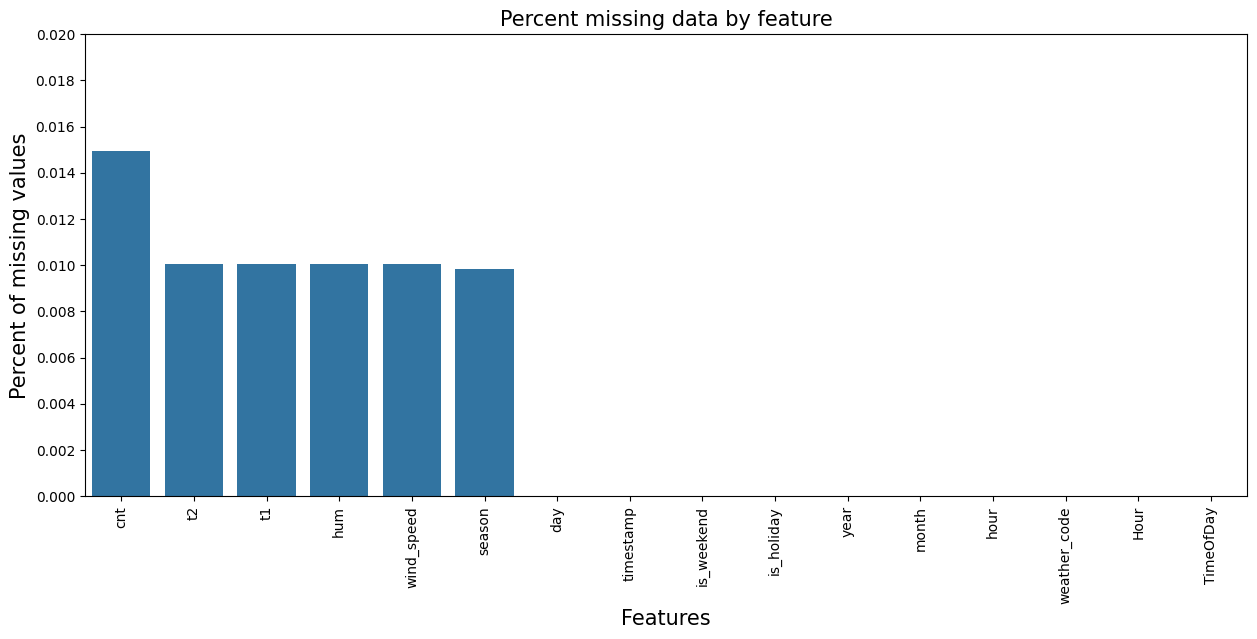

In [17]:
total = df.isnull().sum().sort_values(ascending=False)
percent = (df.isnull().sum()/df.isnull().count()).sort_values(ascending=False)
missing_data = pd.concat([total, percent], axis=1, keys=['Total', 'Percent'])
f, ax = plt.subplots(figsize=(15, 6))
plt.xticks(rotation=90)
sns.barplot(x=missing_data.index, y=missing_data['Percent'])
plt.xlabel('Features', fontsize=15)
plt.ylabel('Percent of missing values', fontsize=15)
plt.title('Percent missing data by feature', fontsize=15)
plt.yticks(np.arange(0, 0.021, 0.002)) # Set y-axis ticks from 0.0 to 0.02 with increments of 0.002
missing_data.head()

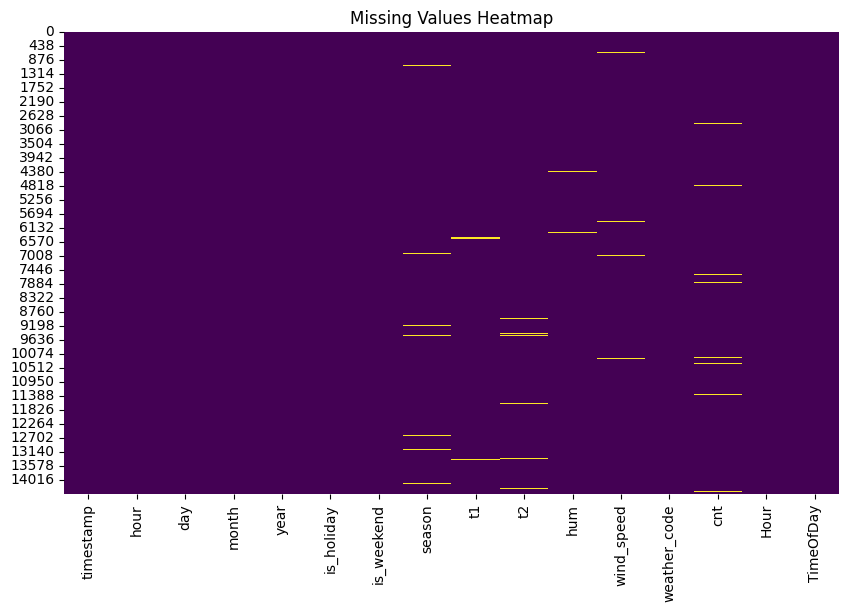

In [18]:
#Visualized missing values
plt.figure(figsize=(10, 6))
sns.heatmap(df.isnull(), cbar=False, cmap='viridis')
plt.title('Missing Values Heatmap')
plt.show()

In [19]:
df[df.isnull().any(axis=1)]

,timestamp,hour,day,month,year,is_holiday,is_weekend,season,t1,t2,hum,wind_speed,weather_code,cnt,Hour,TimeOfDay
14,2015-01-04 14:00:00,14,4,1,2015,0.0,1.0,Winter,2.5,-40.0,90.0,8.0,3.0,NaN,14,Afternoon
16,2015-01-04 16:00:00,16,4,1,2015,0.0,1.0,Winter,3.0,0.0,93.0,12.0,3.0,NaN,16,Afternoon
50,2015-01-06 02:00:00,2,6,1,2015,0.0,0.0,Winter,NaN,6.0,76.0,11.0,4.0,33.0,2,Early Morning
65,2015-01-06 17:00:00,17,6,1,2015,0.0,0.0,Winter,7.5,88.0,71.0,22.0,1.0,NaN,17,Afternoon
84,2015-01-07 12:00:00,12,7,1,2015,0.0,0.0,Winter,9.0,NaN,76.0,27.0,2.0,913.0,12,Afternoon
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14341,2016-08-27 08:00:00,8,27,8,2016,0.0,1.0,NaN,21.0,21.0,69.0,19.0,1.0,581.0,8,Morning
14360,2016-08-28 03:00:00,3,28,8,2016,0.0,1.0,Summer,20.5,20.5,NaN,16.0,3.0,297.0,3,Early Morning
14366,2016-08-28 09:00:00,9,28,8,2016,0.0,1.0,Summer,20.0,20.0,71.0,20.0,3.0,NaN,9,Morning
14381,2016-08-29 00:00:00,0,29,8,2016,1.0,0.0,Summer,18.5,18.5,83.0,9.0,3.0,NaN,0,Early Morning


## Handle missing values

### "season' handle

In [20]:
#showing that the missing values in 'season' columns is Missing Completely at Random (MCAR)
#and the missing values are extremetely small (142 out of 14453)
# Removing the missing values

In [21]:
df.dropna(subset=['season'], inplace=True)

##"T1" and "T2" handle

In [22]:
#t2 and t2 nearly the same
#However, the proportion of missing values is small, so I choose to replace them with the median
#replace with median because the distribution of t1, t2 is not shewed, making sure not affect negatively to distribution

In [23]:
df['t1'] = df['t1'].fillna(df['t1'].median())
df['t2'] = df['t2'].fillna(df['t2'].median())

In [24]:
from sklearn.impute import KNNImputer

# Select the column(s) for imputation
cols_to_impute = ['t2']

# Initialize the KNNImputer
# n_neighbors is the number of neighboring samples to use for imputation
knn_imputer = KNNImputer(n_neighbors=5) # You can adjust n_neighbors

# Apply KNN imputation to the selected column(s)
# The imputer returns a numpy array, so we convert it back to a pandas DataFrame
df[cols_to_impute] = knn_imputer.fit_transform(df[cols_to_impute])

print("Missing values in 't2' column after KNN imputation:")
print(df['t2'].isnull().sum())

Missing values in 't2' column after KNN imputation:
0


##"Wind_Speed" handle

In [25]:
#seeing the distribution of wind_speed is highly positve shewed, so that I decide to replace missing values to median to reduce shewness and less affecting outliers.


In [26]:
df['wind_speed'] = df['wind_speed'].fillna(df['wind_speed'].median())

##"Hum" Handle

In [27]:
df['hum'] = df['hum'].apply(lambda x: np.nan if x < 0 or x > 100 else x)

In [28]:
#Choosing replace invalid values with missing values because:
  #values outside the 0-100% range are physically impossible. Likey data entry errors or measurements issues. Keeping them whould shew the analysis
  #converting these to missing values, can easier to handle them using the same imputation techniques for other missing values.

In [29]:
# then impute these missing values with the median, because it is less affected by the outliers and distribution

In [30]:
df['hum'] = df['hum'].fillna(df['hum'].median())

##"cnt" handle

In [31]:
#given that the percentage of missing values in'cnt' is relatively small (144 of out 14453), removing these rows is unlikely to signifincatly impact the overal size of the dataset or training process.
#Because it is the target variable, removing them ensures that model is trained and evaluated only on complete and observed target values.

In [32]:
df = df.dropna(subset=['cnt'])

## Deeper cleaning

In [33]:
df = df[(df['t1']<37) & (df['t1']>-5.6)]

In [34]:
df = df[(df['t2']<37) & (df['t2']>-5.6)]

In [35]:
df = df[(df['hum']<100) & (df['hum']>7)]

In [36]:
df = df[(df['wind_speed']>0) & (df['wind_speed']<=62)]

In [37]:
df = df[(df['cnt']>0) & (df['cnt']<13000)]

##Checking mising values again

In [38]:
df.isnull().sum()

,0
timestamp,0
hour,0
day,0
month,0
year,0
is_holiday,0
is_weekend,0
season,0
t1,0
t2,0


In [39]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 12927 entries, 0 to 14452
Data columns (total 16 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   timestamp     12927 non-null  datetime64[ns]
 1   hour          12927 non-null  int64         
 2   day           12927 non-null  int64         
 3   month         12927 non-null  int64         
 4   year          12927 non-null  int64         
 5   is_holiday    12927 non-null  float64       
 6   is_weekend    12927 non-null  float64       
 7   season        12927 non-null  object        
 8   t1            12927 non-null  float64       
 9   t2            12927 non-null  float64       
 10  hum           12927 non-null  float64       
 11  wind_speed    12927 non-null  float64       
 12  weather_code  12927 non-null  float64       
 13  cnt           12927 non-null  float64       
 14  Hour          12927 non-null  int32         
 15  TimeOfDay     12927 non-null  object     

#Univariate analysis

##Numerical variables

###Overview

In [40]:
pd.options.display.float_format ='{:.2f}'.format
df.describe()

,timestamp,hour,day,month,year,is_holiday,is_weekend,t1,t2,hum,wind_speed,weather_code,cnt,Hour
count,12927,12927.00,12927.00,12927.00,12927.00,12927.00,12927.00,12927.00,12927.00,12927.00,12927.00,12927.00,12927.00,12927.00
mean,2015-11-02 09:45:50.893478912,11.53,15.81,5.73,2015.40,0.02,0.28,12.68,11.73,71.14,16.50,2.73,1153.25,11.53
min,2015-01-04 00:00:00,0.00,1.00,1.00,2015.00,0.00,0.00,-1.50,-5.50,23.00,2.00,1.00,11.00,0.00
25%,2015-06-02 06:30:00,6.00,8.00,3.00,2015.00,0.00,0.00,8.50,6.00,62.00,11.00,1.00,261.00,6.00
50%,2015-11-01 17:00:00,12.00,16.00,6.00,2015.00,0.00,0.00,13.00,13.00,73.50,16.00,2.00,849.00,12.00
75%,2016-04-03 19:30:00,18.00,23.00,8.00,2016.00,0.00,1.00,16.50,16.50,82.00,21.00,3.00,1707.50,18.00
max,2016-08-31 23:00:00,23.00,31.00,12.00,2016.00,1.00,1.00,34.00,34.00,97.00,56.50,26.00,7860.00,23.00
std,NaN,6.92,8.77,3.17,0.49,0.14,0.45,5.57,6.64,14.08,7.88,2.34,1089.18,6.92


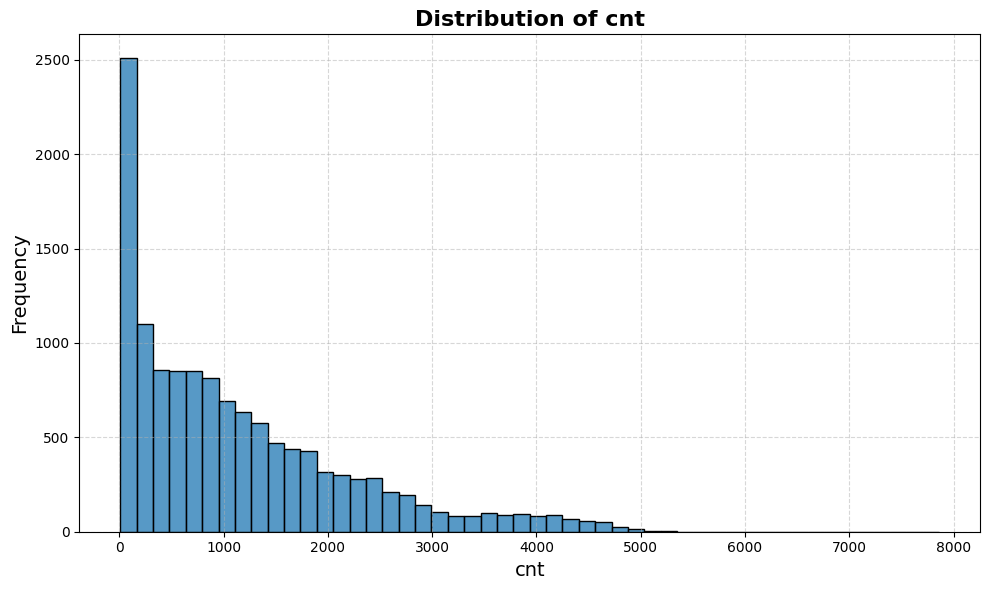

In [41]:
plt.figure(figsize=(10, 6))
sns.histplot(data=df, x='cnt', bins=50, kde=False)
plt.title('Distribution of cnt', fontsize=16, fontweight='bold')
plt.xlabel('cnt', fontsize=14)
plt.ylabel('Frequency', fontsize=14)

plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()

plt.show()

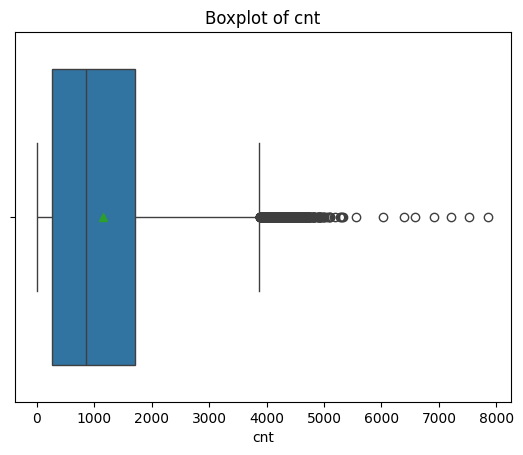

In [42]:
sns.boxplot(data=df, x='cnt', showmeans=True)
title = 'Boxplot of cnt'
plt.title(title)
plt.show()

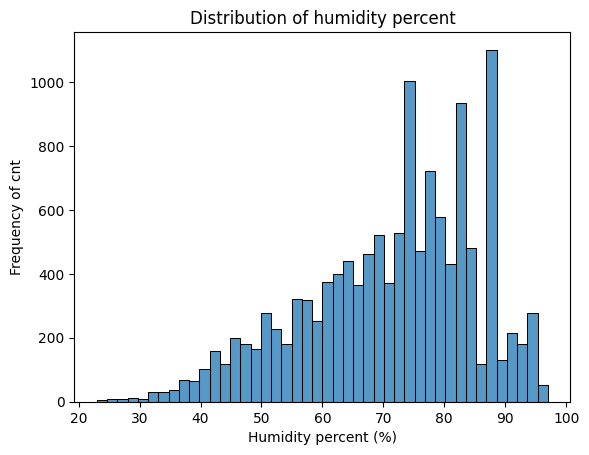

In [43]:
sns.histplot(data=df, x='hum')
title = 'Distribution of humidity percent'
xtitle = 'Humidity percent (%)'
ytitle = 'Frequency of cnt'
plt.xlabel(xtitle)
plt.ylabel(ytitle)
plt.title(title)

plt.show()

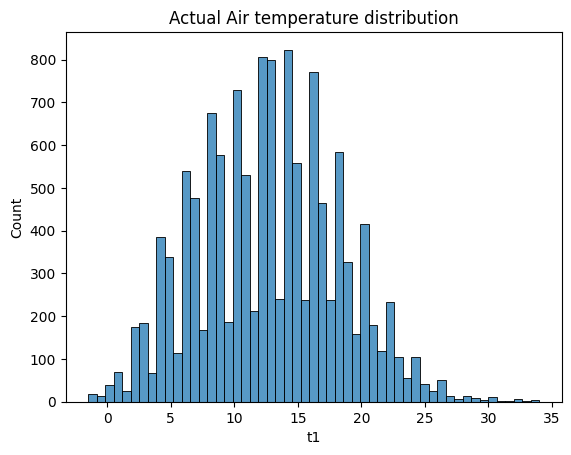

In [44]:
sns.histplot(data=df, x='t1')
title = 'Actual Air temperature distribution'
plt.title(title)
plt.show()

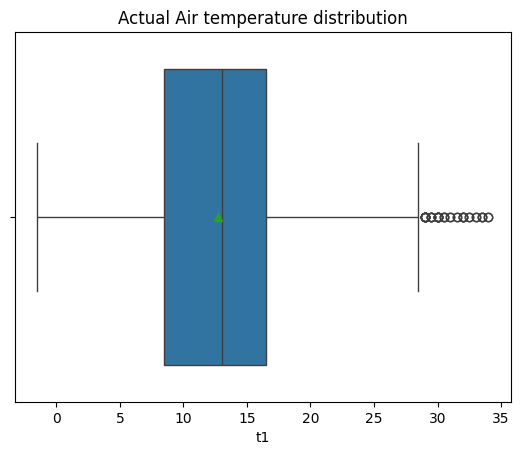

In [45]:
sns.boxplot(data=df, x='t1',  showmeans=True)
title = 'Actual Air temperature distribution'
plt.title(title)
plt.show()

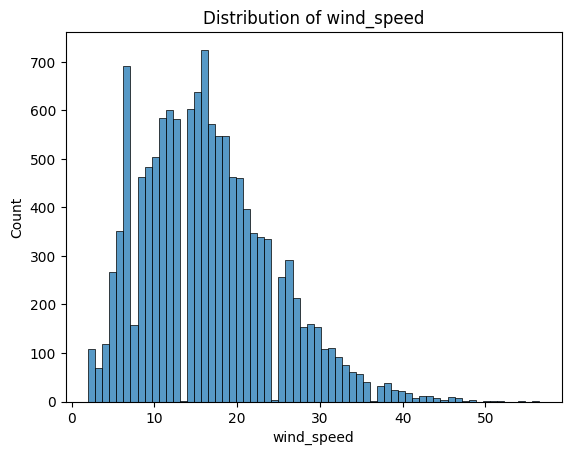

In [46]:
sns.histplot(data=df, x='wind_speed')
title = 'Distribution of wind_speed'
plt.title(title)
plt.show()

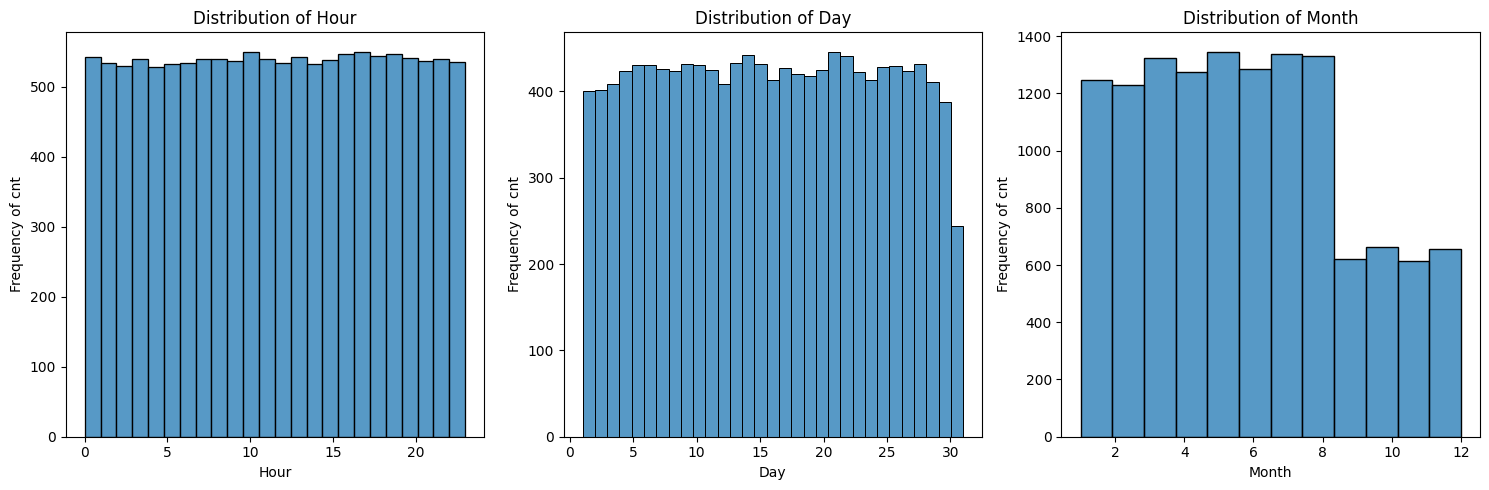

In [47]:
#creat the histogram for hour, day, month

# Create histograms for 'hour', 'day', and 'month'
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
sns.histplot(data=df, x='hour', bins=24, kde=False)
plt.title('Distribution of Hour')
plt.xlabel('Hour')
plt.ylabel('Frequency of cnt')

plt.subplot(1, 3, 2)
sns.histplot(data=df, x='day', bins=31, kde=False)
plt.title('Distribution of Day')
plt.xlabel('Day')
plt.ylabel('Frequency of cnt')

plt.subplot(1, 3, 3)
sns.histplot(data=df, x='month', bins=12, kde=False)
plt.title('Distribution of Month')
plt.xlabel('Month')
plt.ylabel('Frequency of cnt')

plt.tight_layout()
plt.show()

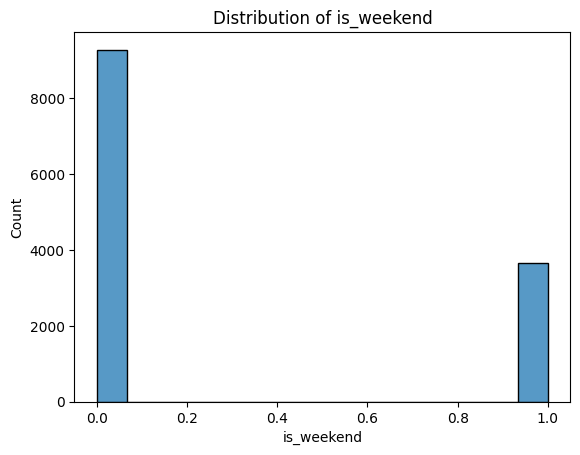

In [48]:
sns.histplot(data=df, x='is_weekend')
title = 'Distribution of is_weekend'
plt.title(title)
plt.show()

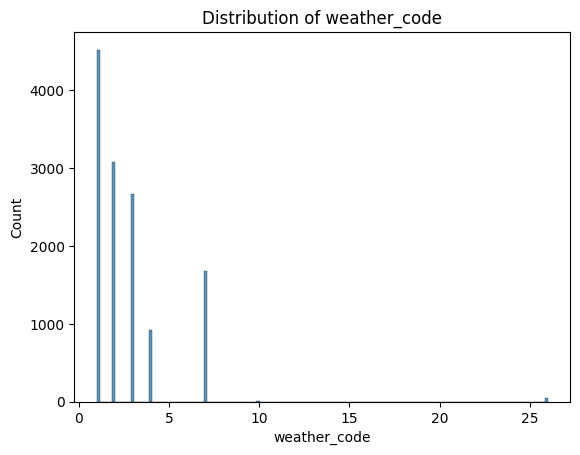

In [49]:
sns.histplot(data=df, x='weather_code')
title = 'Distribution of weather_code'
plt.title(title)
plt.show()

### Identify outliers

1. 'cnt' column

In [50]:
Q1 = df['cnt'].quantile(0.25)
Q3 = df['cnt'].quantile(0.75)
IQR = Q3 - Q1


lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR


outliers = df[(df['cnt'] < lower_bound) | (df['cnt'] > upper_bound)]


num_outliers = outliers.shape[0]


print(f'Any cnt < ${lower_bound} or cnt > ${upper_bound} are identified as outliers')
print(f'Number of outliers in """ column: {num_outliers}')
print('Some sample outliers')
outliers

Any cnt < $-1908.75 or cnt > $3877.25 are identified as outliers
Number of outliers in """ column: 445
Some sample outliers


,timestamp,hour,day,month,year,is_holiday,is_weekend,season,t1,t2,hum,wind_speed,weather_code,cnt,Hour,TimeOfDay
223,2015-01-13 08:00:00,8,13,1,2015,0.00,0.00,Winter,9.00,6.50,73.50,16.00,2.00,3960.00,8,Morning
247,2015-01-14 08:00:00,8,14,1,2015,0.00,0.00,Winter,4.00,-1.00,70.00,26.00,2.00,3904.00,8,Morning
1542,2015-03-09 08:00:00,8,9,3,2015,0.00,0.00,Spring,7.50,5.50,71.00,11.00,1.00,3886.00,8,Morning
1566,2015-03-10 08:00:00,8,10,3,2015,0.00,0.00,Spring,8.00,5.50,73.50,12.00,1.00,4033.00,8,Morning
1590,2015-03-11 08:00:00,8,11,3,2015,0.00,0.00,Spring,6.00,3.50,81.50,12.00,1.00,4053.00,8,Morning
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14422,2016-08-30 17:00:00,17,30,8,2016,0.00,0.00,Summer,25.50,25.50,39.50,12.00,1.00,4889.00,17,Afternoon
14423,2016-08-30 18:00:00,18,30,8,2016,0.00,0.00,Summer,24.50,24.50,43.00,13.00,1.00,4703.00,18,Evening
14437,2016-08-31 08:00:00,8,31,8,2016,0.00,0.00,Summer,18.00,18.00,64.00,12.00,1.00,4807.00,8,Morning
14446,2016-08-31 17:00:00,17,31,8,2016,0.00,0.00,Summer,23.00,23.00,57.00,17.50,2.00,4522.00,17,Afternoon


2. 'hum' column

In [51]:
Q1 = df['hum'].quantile(0.25)
Q3 = df['hum'].quantile(0.75)
IQR = Q3 - Q1


lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR


outliers = df[(df['hum'] < lower_bound) | (df['hum'] > upper_bound)]


num_outliers = outliers.shape[0]


print(f'Any humidity < ${lower_bound} or humidity > ${upper_bound} are identified as outliers')
print(f'Number of outliers in """ column: {num_outliers}')
print('Some sample outliers')
outliers

Any humidity < $32.0 or humidity > $112.0 are identified as outliers
Number of outliers in """ column: 45
Some sample outliers


,timestamp,hour,day,month,year,is_holiday,is_weekend,season,t1,t2,hum,wind_speed,weather_code,cnt,Hour,TimeOfDay
1619,2015-03-12 13:00:00,13,12,3,2015,0.00,0.00,Spring,14.00,14.00,26.00,21.00,1.00,1282.00,13,Afternoon
1620,2015-03-12 14:00:00,14,12,3,2015,0.00,0.00,Spring,13.00,13.00,27.00,22.00,1.00,1192.00,14,Afternoon
1621,2015-03-12 15:00:00,15,12,3,2015,0.00,0.00,Spring,13.00,13.00,31.00,18.00,1.00,1258.00,15,Afternoon
2431,2015-04-15 15:00:00,15,15,4,2015,0.00,0.00,Spring,24.00,23.00,29.50,20.50,1.00,1888.00,15,Afternoon
2432,2015-04-15 16:00:00,16,15,4,2015,0.00,0.00,Spring,25.00,24.00,29.00,18.50,1.00,2455.00,16,Afternoon
2433,2015-04-15 17:00:00,17,15,4,2015,0.00,0.00,Spring,23.50,22.50,29.00,19.50,1.00,4446.00,17,Afternoon
2741,2015-04-28 13:00:00,13,28,4,2015,0.00,0.00,Spring,12.50,12.50,29.00,29.00,1.00,1324.00,13,Afternoon
2745,2015-04-28 17:00:00,17,28,4,2015,0.00,0.00,Spring,13.50,13.50,28.50,29.00,1.00,3794.00,17,Afternoon
3297,2015-05-21 17:00:00,17,21,5,2015,0.00,0.00,Spring,13.00,20.00,30.00,20.50,1.00,3810.00,17,Afternoon
3298,2015-05-21 18:00:00,18,21,5,2015,0.00,0.00,Spring,19.50,19.50,27.00,19.50,1.00,3764.00,18,Evening


3. 'wind_speed' column

In [52]:
Q1 = df['wind_speed'].quantile(0.25)
Q3 = df['wind_speed'].quantile(0.75)
IQR = Q3 - Q1


lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR


outliers = df[(df['wind_speed'] < lower_bound) | (df['wind_speed'] > upper_bound)]


num_outliers = outliers.shape[0]


print(f'Any wind speed < ${lower_bound} or wind speed > ${upper_bound} are identified as outliers')
print(f'Number of outliers in """ column: {num_outliers}')
print('Some sample outliers')
outliers

Any wind speed < $-4.0 or wind speed > $36.0 are identified as outliers
Number of outliers in """ column: 205
Some sample outliers


,timestamp,hour,day,month,year,is_holiday,is_weekend,season,t1,t2,hum,wind_speed,weather_code,cnt,Hour,TimeOfDay
135,2015-01-09 16:00:00,16,9,1,2015,0.00,0.00,Spring,13.00,13.00,79.50,37.00,7.00,1229.00,16,Afternoon
138,2015-01-09 19:00:00,19,9,1,2015,0.00,0.00,Winter,15.50,15.50,77.00,41.00,7.00,1094.00,19,Evening
139,2015-01-09 20:00:00,20,9,1,2015,0.00,0.00,Winter,15.00,15.00,72.00,44.00,3.00,686.00,20,Evening
140,2015-01-09 21:00:00,21,9,1,2015,0.00,0.00,Winter,15.00,15.00,68.00,41.00,3.00,443.00,21,Evening
141,2015-01-09 22:00:00,22,9,1,2015,0.00,0.00,Winter,15.00,15.00,68.00,40.00,3.00,464.00,22,Evening
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10939,2016-04-06 15:00:00,15,6,4,2016,0.00,0.00,Spring,11.50,11.50,51.00,36.50,7.00,896.00,15,Afternoon
10940,2016-04-06 16:00:00,16,6,4,2016,0.00,0.00,Spring,11.50,11.50,45.50,40.50,2.00,1496.00,16,Afternoon
10941,2016-04-06 17:00:00,17,6,4,2016,0.00,0.00,Spring,11.50,11.50,44.00,39.00,7.00,2966.00,17,Afternoon
11035,2016-04-10 16:00:00,16,10,4,2016,0.00,1.00,Spring,10.50,8.50,60.00,38.00,1.00,2124.00,16,Afternoon


4. 'weather code' column

In [53]:
Q1 = df['weather_code'].quantile(0.25)
Q3 = df['weather_code'].quantile(0.75)
IQR = Q3 - Q1


lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR


outliers = df[(df['weather_code'] < lower_bound) | (df['weather_code'] > upper_bound)]


num_outliers = outliers.shape[0]


print(f'Any code < ${lower_bound} or code  > ${upper_bound} are identified as outliers')
print(f'Number of outliers in """ column: {num_outliers}')
print('Some sample outliers')
outliers

Any code < $-2.0 or code  > $6.0 are identified as outliers
Number of outliers in """ column: 1734
Some sample outliers


,timestamp,hour,day,month,year,is_holiday,is_weekend,season,t1,t2,hum,wind_speed,weather_code,cnt,Hour,TimeOfDay
56,2015-01-06 08:00:00,8,6,1,2015,0.00,0.00,Winter,9.00,7.00,82.00,12.00,7.00,3534.00,8,Morning
57,2015-01-06 09:00:00,9,6,1,2015,0.00,0.00,Winter,9.00,6.50,87.00,16.00,7.00,1573.00,9,Morning
60,2015-01-06 12:00:00,12,6,1,2015,0.00,0.00,Winter,11.00,11.00,73.50,19.00,7.00,395.00,12,Afternoon
92,2015-01-07 21:00:00,21,7,1,2015,0.00,0.00,Winter,10.00,7.00,82.00,27.00,7.00,516.00,21,Evening
93,2015-01-07 22:00:00,22,7,1,2015,0.00,0.00,Winter,10.00,7.00,82.00,27.00,7.00,414.00,22,Evening
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14283,2016-08-24 22:00:00,22,24,8,2016,0.00,0.00,Summer,23.00,23.00,69.00,11.00,7.00,926.00,22,Evening
14310,2016-08-26 01:00:00,1,26,8,2016,0.00,0.00,Summer,23.00,23.00,78.00,10.00,7.00,158.00,1,Early Morning
14348,2016-08-27 15:00:00,15,27,8,2016,0.00,1.00,Summer,22.50,22.50,67.00,30.50,7.00,2641.00,15,Afternoon
14368,2016-08-28 11:00:00,11,28,8,2016,0.00,1.00,Summer,20.00,20.00,73.50,18.50,7.00,1449.00,11,Morning


5. temperature

In [54]:
Q1 = df['t1'].quantile(0.25)
Q3 = df['t1'].quantile(0.75)
IQR = Q3 - Q1


lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR


outliers = df[(df['t1'] < lower_bound) | (df['t1'] > upper_bound)]


num_outliers = outliers.shape[0]


print(f'Any code < ${lower_bound} or code  > ${upper_bound} are identified as outliers')
print(f'Number of outliers in """ column: {num_outliers}')
print('Some sample outliers')
outliers

Any code < $-3.5 or code  > $28.5 are identified as outliers
Number of outliers in """ column: 40
Some sample outliers


,timestamp,hour,day,month,year,is_holiday,is_weekend,season,t1,t2,hum,wind_speed,weather_code,cnt,Hour,TimeOfDay
4251,2015-06-30 14:00:00,14,30,6,2015,0.00,0.00,Summer,29.00,28.00,26.00,15.00,1.00,1783.00,14,Afternoon
4271,2015-07-01 10:00:00,10,1,7,2015,0.00,0.00,Summer,30.00,30.00,43.00,20.00,1.00,1299.00,10,Morning
4272,2015-07-01 11:00:00,11,1,7,2015,0.00,0.00,Summer,33.00,33.00,34.00,22.00,1.00,1374.00,11,Morning
4273,2015-07-01 12:00:00,12,1,7,2015,0.00,0.00,Summer,32.00,32.00,36.00,19.50,1.00,1654.00,12,Afternoon
4274,2015-07-01 13:00:00,13,1,7,2015,0.00,0.00,Summer,31.50,31.50,38.00,21.00,1.00,1753.00,13,Afternoon
4275,2015-07-01 14:00:00,14,1,7,2015,0.00,0.00,Summer,33.00,33.00,34.00,18.00,1.00,1710.00,14,Afternoon
4276,2015-07-01 15:00:00,15,1,7,2015,0.00,0.00,Summer,33.50,33.50,34.00,22.00,1.00,1904.00,15,Afternoon
4277,2015-07-01 16:00:00,16,1,7,2015,0.00,0.00,Summer,33.50,33.50,35.00,21.00,1.00,2575.00,16,Afternoon
4278,2015-07-01 17:00:00,17,1,7,2015,0.00,0.00,Summer,34.00,34.00,33.00,20.50,1.00,4617.00,17,Afternoon
4279,2015-07-01 18:00:00,18,1,7,2015,0.00,0.00,Summer,34.00,34.00,33.00,20.50,1.00,4604.00,18,Evening


###Handles outliers

1. 'cnt' column

In [55]:
df_transformed = df.copy()
df_transformed['cnt'] = np.log1p(df_transformed['cnt'])

In [56]:
# Display results
print(f"Original dataset size: {df.shape[0]}")
print(f"Example of log-transformed prices:\n{df_transformed[['cnt']].head()}")

Original dataset size: 12927
Example of log-transformed prices:
   cnt
0 5.21
1 4.93
4 3.87
5 3.85
8 4.88


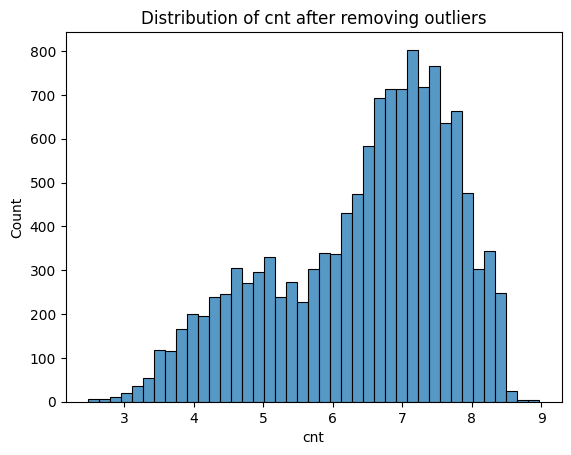

In [57]:
sns.histplot(df_transformed['cnt'])
title = 'Distribution of cnt after removing outliers'
plt.title(title)
plt.show()

2.'hum' column

Based on the distribution of the 'hum' column and the relatively small number of outliers identified, I will handle the outliers by capping them with the upper and lower bounds calculated using the IQR method. Capping is chosen over removal to retain more data points, as humidity values, even if extreme, can still be valid measurements within a certain range. The IQR method is suitable for identifying outliers in this distribution.

In [58]:

df_capped = df.copy()
df_capped['hum'] = np.where(df_capped['hum'] < lower_bound, lower_bound, df_capped['hum'])
df_capped['hum'] = np.where(df_capped['hum'] > upper_bound, upper_bound, df_capped['hum'])

print(f'Capped values in hum column: values below {lower_bound} are set to {lower_bound}, and values above {upper_bound} are set to {upper_bound}')

Capped values in hum column: values below -3.5 are set to -3.5, and values above 28.5 are set to 28.5


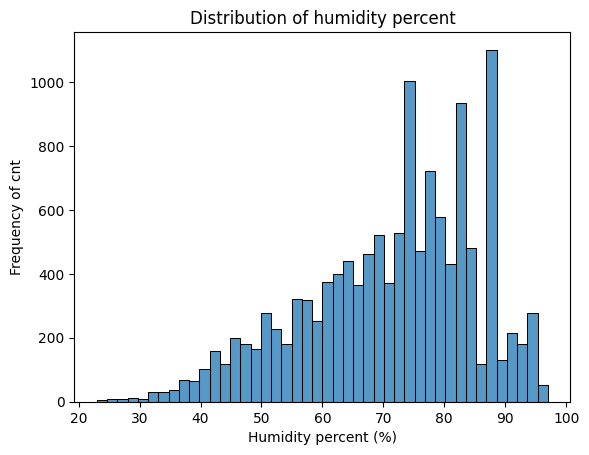

In [59]:
sns.histplot(df_transformed['hum'])
title = 'Distribution of humidity percent'
xtitle = 'Humidity percent (%)'
ytitle = 'Frequency of cnt'
plt.xlabel(xtitle)
plt.ylabel(ytitle)
plt.title(title)
plt.show()

3. 'wind_speed' column

Seeing the distribution of 'wind_speed' is highly positively skewed and contains outliers, I will handle the outliers by capping them with the upper and lower bounds calculated using the IQR method. Tranformation is chosen to mitigate the impact of extreme values on the model while retaining as much data as possible. The IQR method is appropriate for identifying outliers in a skewed distribution.

In [60]:
 df.copy()
df_capped['wind_speed'] = np.where(df_capped['wind_speed'] < lower_bound, lower_bound, df_capped['wind_speed'])
df_capped['wind_speed'] = np.where(df_capped['wind_speed'] > upper_bound, upper_bound, df_capped['wind_speed'])

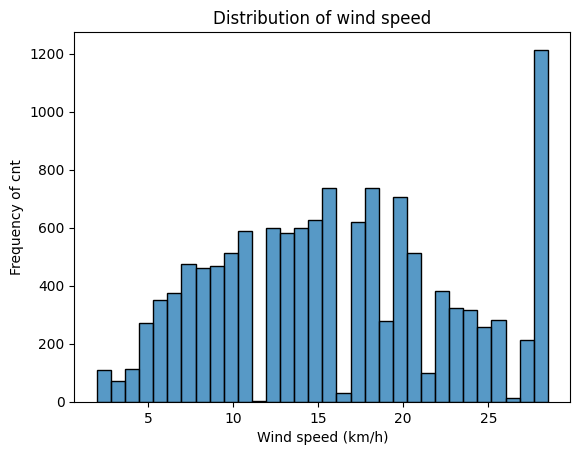

In [61]:
sns.histplot(df_capped['wind_speed'])
title = 'Distribution of wind speed'
xtitle = 'Wind speed (km/h)'
ytitle = 'Frequency of cnt'
plt.xlabel(xtitle)
plt.ylabel(ytitle)
plt.title(title)
plt.show()

4. 't1' column

Based on the distribution of the 't1' column and the identified outliers, I will handle the outliers by capping them with the upper and lower bounds calculated using the IQR method. Capping is chosen to mitigate the impact of extreme values on the model while retaining most of the data. The IQR method is appropriate for identifying outliers in this distribution.

In [62]:
df.copy()
df_capped['t1'] = np.where(df_capped['t1'] < lower_bound, lower_bound, df_capped['t1'])
df_capped['t1'] = np.where(df_capped['t1'] > upper_bound, upper_bound, df_capped['t1'])

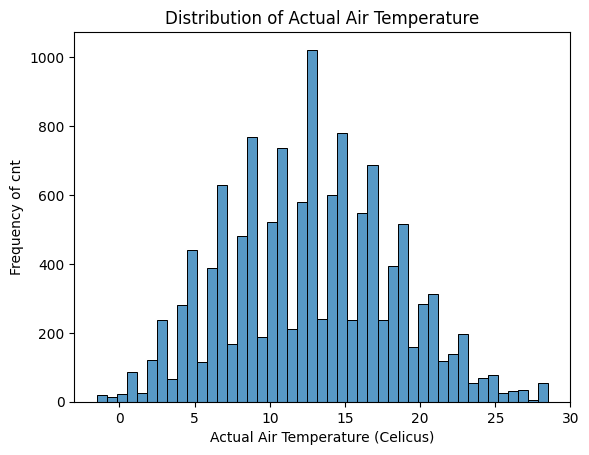

In [63]:
sns.histplot(df_capped['t1'])
title = 'Distribution of Actual Air Temperature'
plt.title(title)
xtitle = 'Actual Air Temperature (Celicus)'
plt.xlabel(xtitle)
ytitle = 'Frequency of cnt'
plt.ylabel(ytitle)
plt.show()

### Lazy EDA for numerical univariate analysis

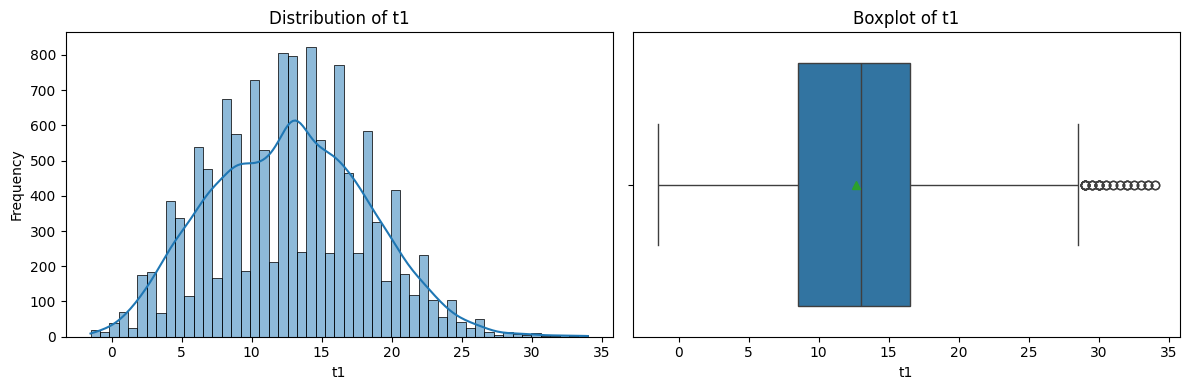

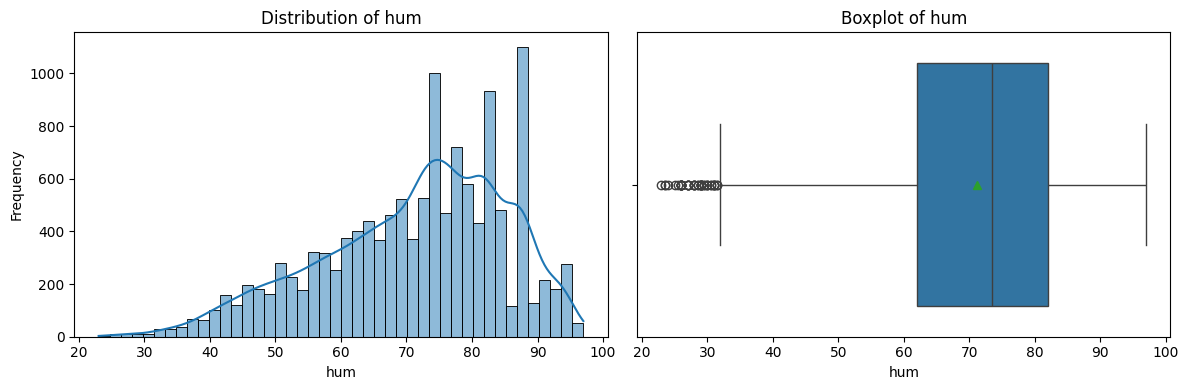

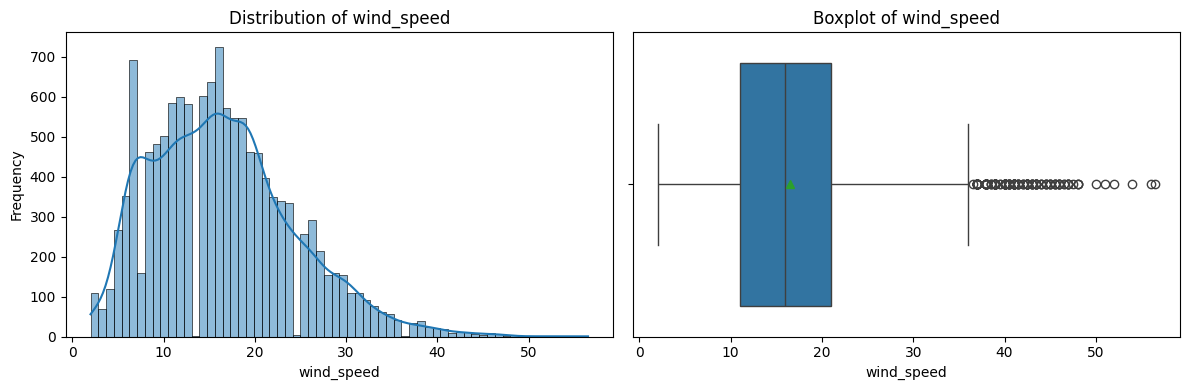

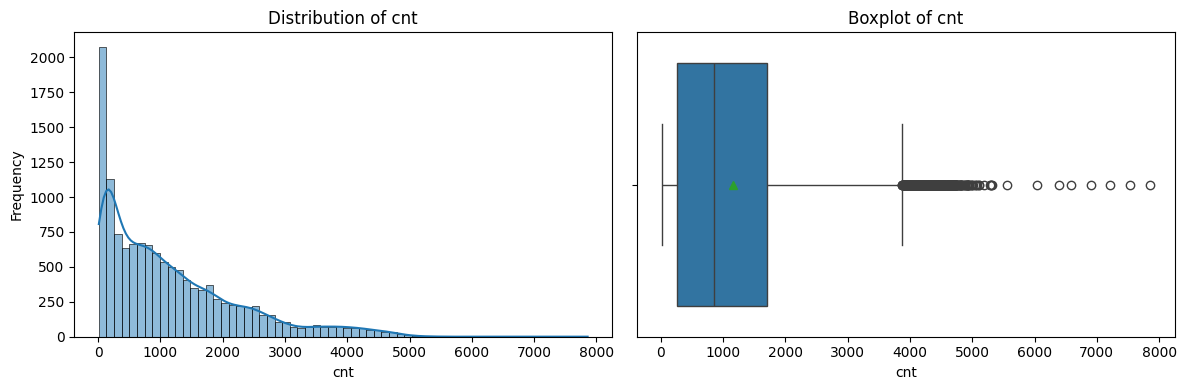

In [64]:
numeric_cols = ['t1', 'hum', 'wind_speed', 'cnt']


for col in numeric_cols:
  plt.figure(figsize=(12, 4))  # Adjust figure size as needed

  # Histplot
  plt.subplot(1, 2, 1)  # Create a subplot for the histplot
  sns.histplot(data=df, x=col, kde=True) #Added KDE for distribution visualization
  plt.title(f'Distribution of {col}')
  plt.xlabel(col)
  plt.ylabel('Frequency')


  # Boxplot
  plt.subplot(1, 2, 2)  # Create a subplot for the boxplot
  sns.boxplot(data=df, x=col, showmeans=True)
  plt.title(f'Boxplot of {col}')
  plt.xlabel(col)

  plt.tight_layout()  # Adjust layout to prevent overlapping
  plt.show()

## Categorical variables

###Overview

In [65]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 12927 entries, 0 to 14452
Data columns (total 16 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   timestamp     12927 non-null  datetime64[ns]
 1   hour          12927 non-null  int64         
 2   day           12927 non-null  int64         
 3   month         12927 non-null  int64         
 4   year          12927 non-null  int64         
 5   is_holiday    12927 non-null  float64       
 6   is_weekend    12927 non-null  float64       
 7   season        12927 non-null  object        
 8   t1            12927 non-null  float64       
 9   t2            12927 non-null  float64       
 10  hum           12927 non-null  float64       
 11  wind_speed    12927 non-null  float64       
 12  weather_code  12927 non-null  float64       
 13  cnt           12927 non-null  float64       
 14  Hour          12927 non-null  int32         
 15  TimeOfDay     12927 non-null  object     

In [66]:
# Define your categorical columns here
categorical_cols = ['season','TimeOfDay']
df[categorical_cols] = df[categorical_cols].astype('category')

df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 12927 entries, 0 to 14452
Data columns (total 16 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   timestamp     12927 non-null  datetime64[ns]
 1   hour          12927 non-null  int64         
 2   day           12927 non-null  int64         
 3   month         12927 non-null  int64         
 4   year          12927 non-null  int64         
 5   is_holiday    12927 non-null  float64       
 6   is_weekend    12927 non-null  float64       
 7   season        12927 non-null  category      
 8   t1            12927 non-null  float64       
 9   t2            12927 non-null  float64       
 10  hum           12927 non-null  float64       
 11  wind_speed    12927 non-null  float64       
 12  weather_code  12927 non-null  float64       
 13  cnt           12927 non-null  float64       
 14  Hour          12927 non-null  int32         
 15  TimeOfDay     12927 non-null  category   

In [67]:
df.describe(include='category')

,season,TimeOfDay
count,12927,12927
unique,4,4
top,Spring,Evening
freq,4043,3242


###Season

In [68]:
df['season'].value_counts()

,count
season,
Spring,4043
Summer,3914
Winter,3096
Fall,1874


In [69]:
# Compute relative frequency of each  type
df['season'].value_counts(normalize=True)

,proportion
season,
Spring,0.31
Summer,0.30
Winter,0.24
Fall,0.14


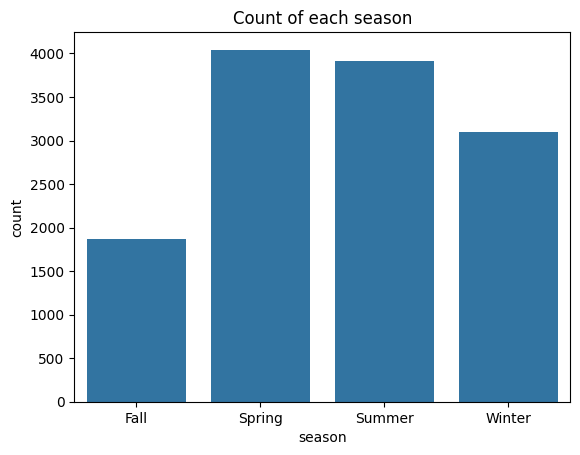

In [70]:
sns.countplot(data=df, x="season")
title = 'Count of each season'
plt.title(title)
plt.show()

###Time of day

In [71]:
df['TimeOfDay'].value_counts()

,count
TimeOfDay,
Evening,3242
Afternoon,3241
Morning,3240
Early Morning,3204


In [72]:
# Compute relative frequency of each  type
df['TimeOfDay'].value_counts(normalize=True)

,proportion
TimeOfDay,
Evening,0.25
Afternoon,0.25
Morning,0.25
Early Morning,0.25


Text(0.5, 1.0, 'Proportion of TimeOfDay')

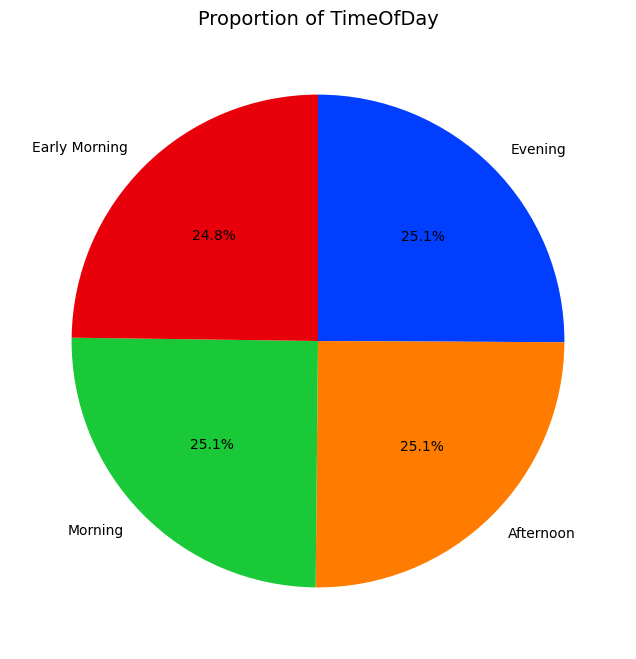

In [73]:

plt.figure(figsize=(8, 8))
type_counts_sorted = df['TimeOfDay'].value_counts().sort_values(ascending=False)

plt.pie(type_counts_sorted, labels=type_counts_sorted.index, autopct='%1.1f%%',
        colors=sns.color_palette("bright"), startangle=90, counterclock=False)


plt.title("Proportion of TimeOfDay", fontsize=14)



#Bivariate Analysis

##Numerical vs Numerical Data

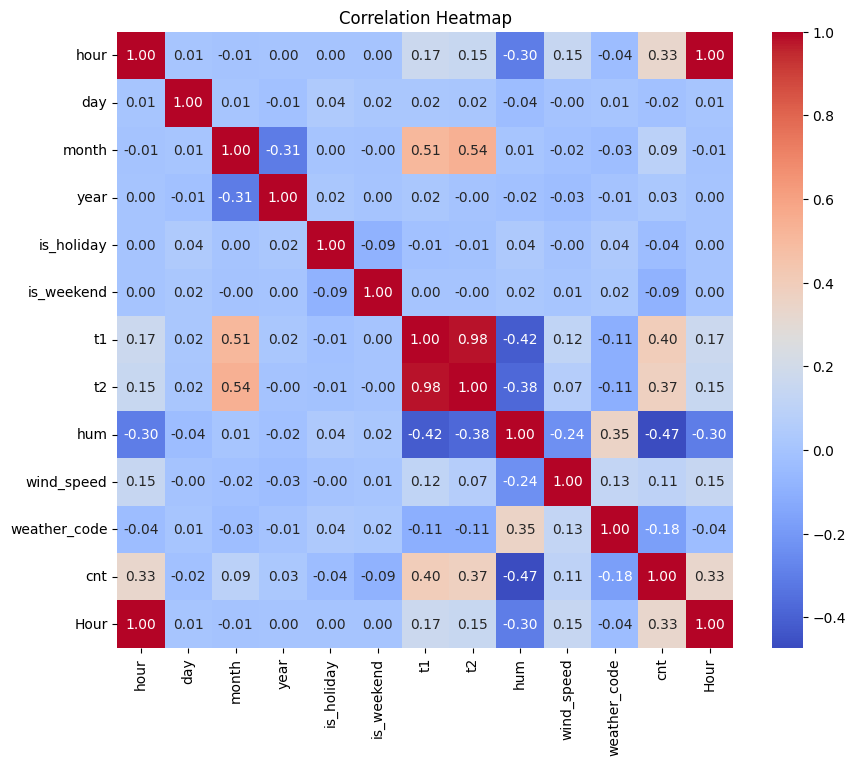

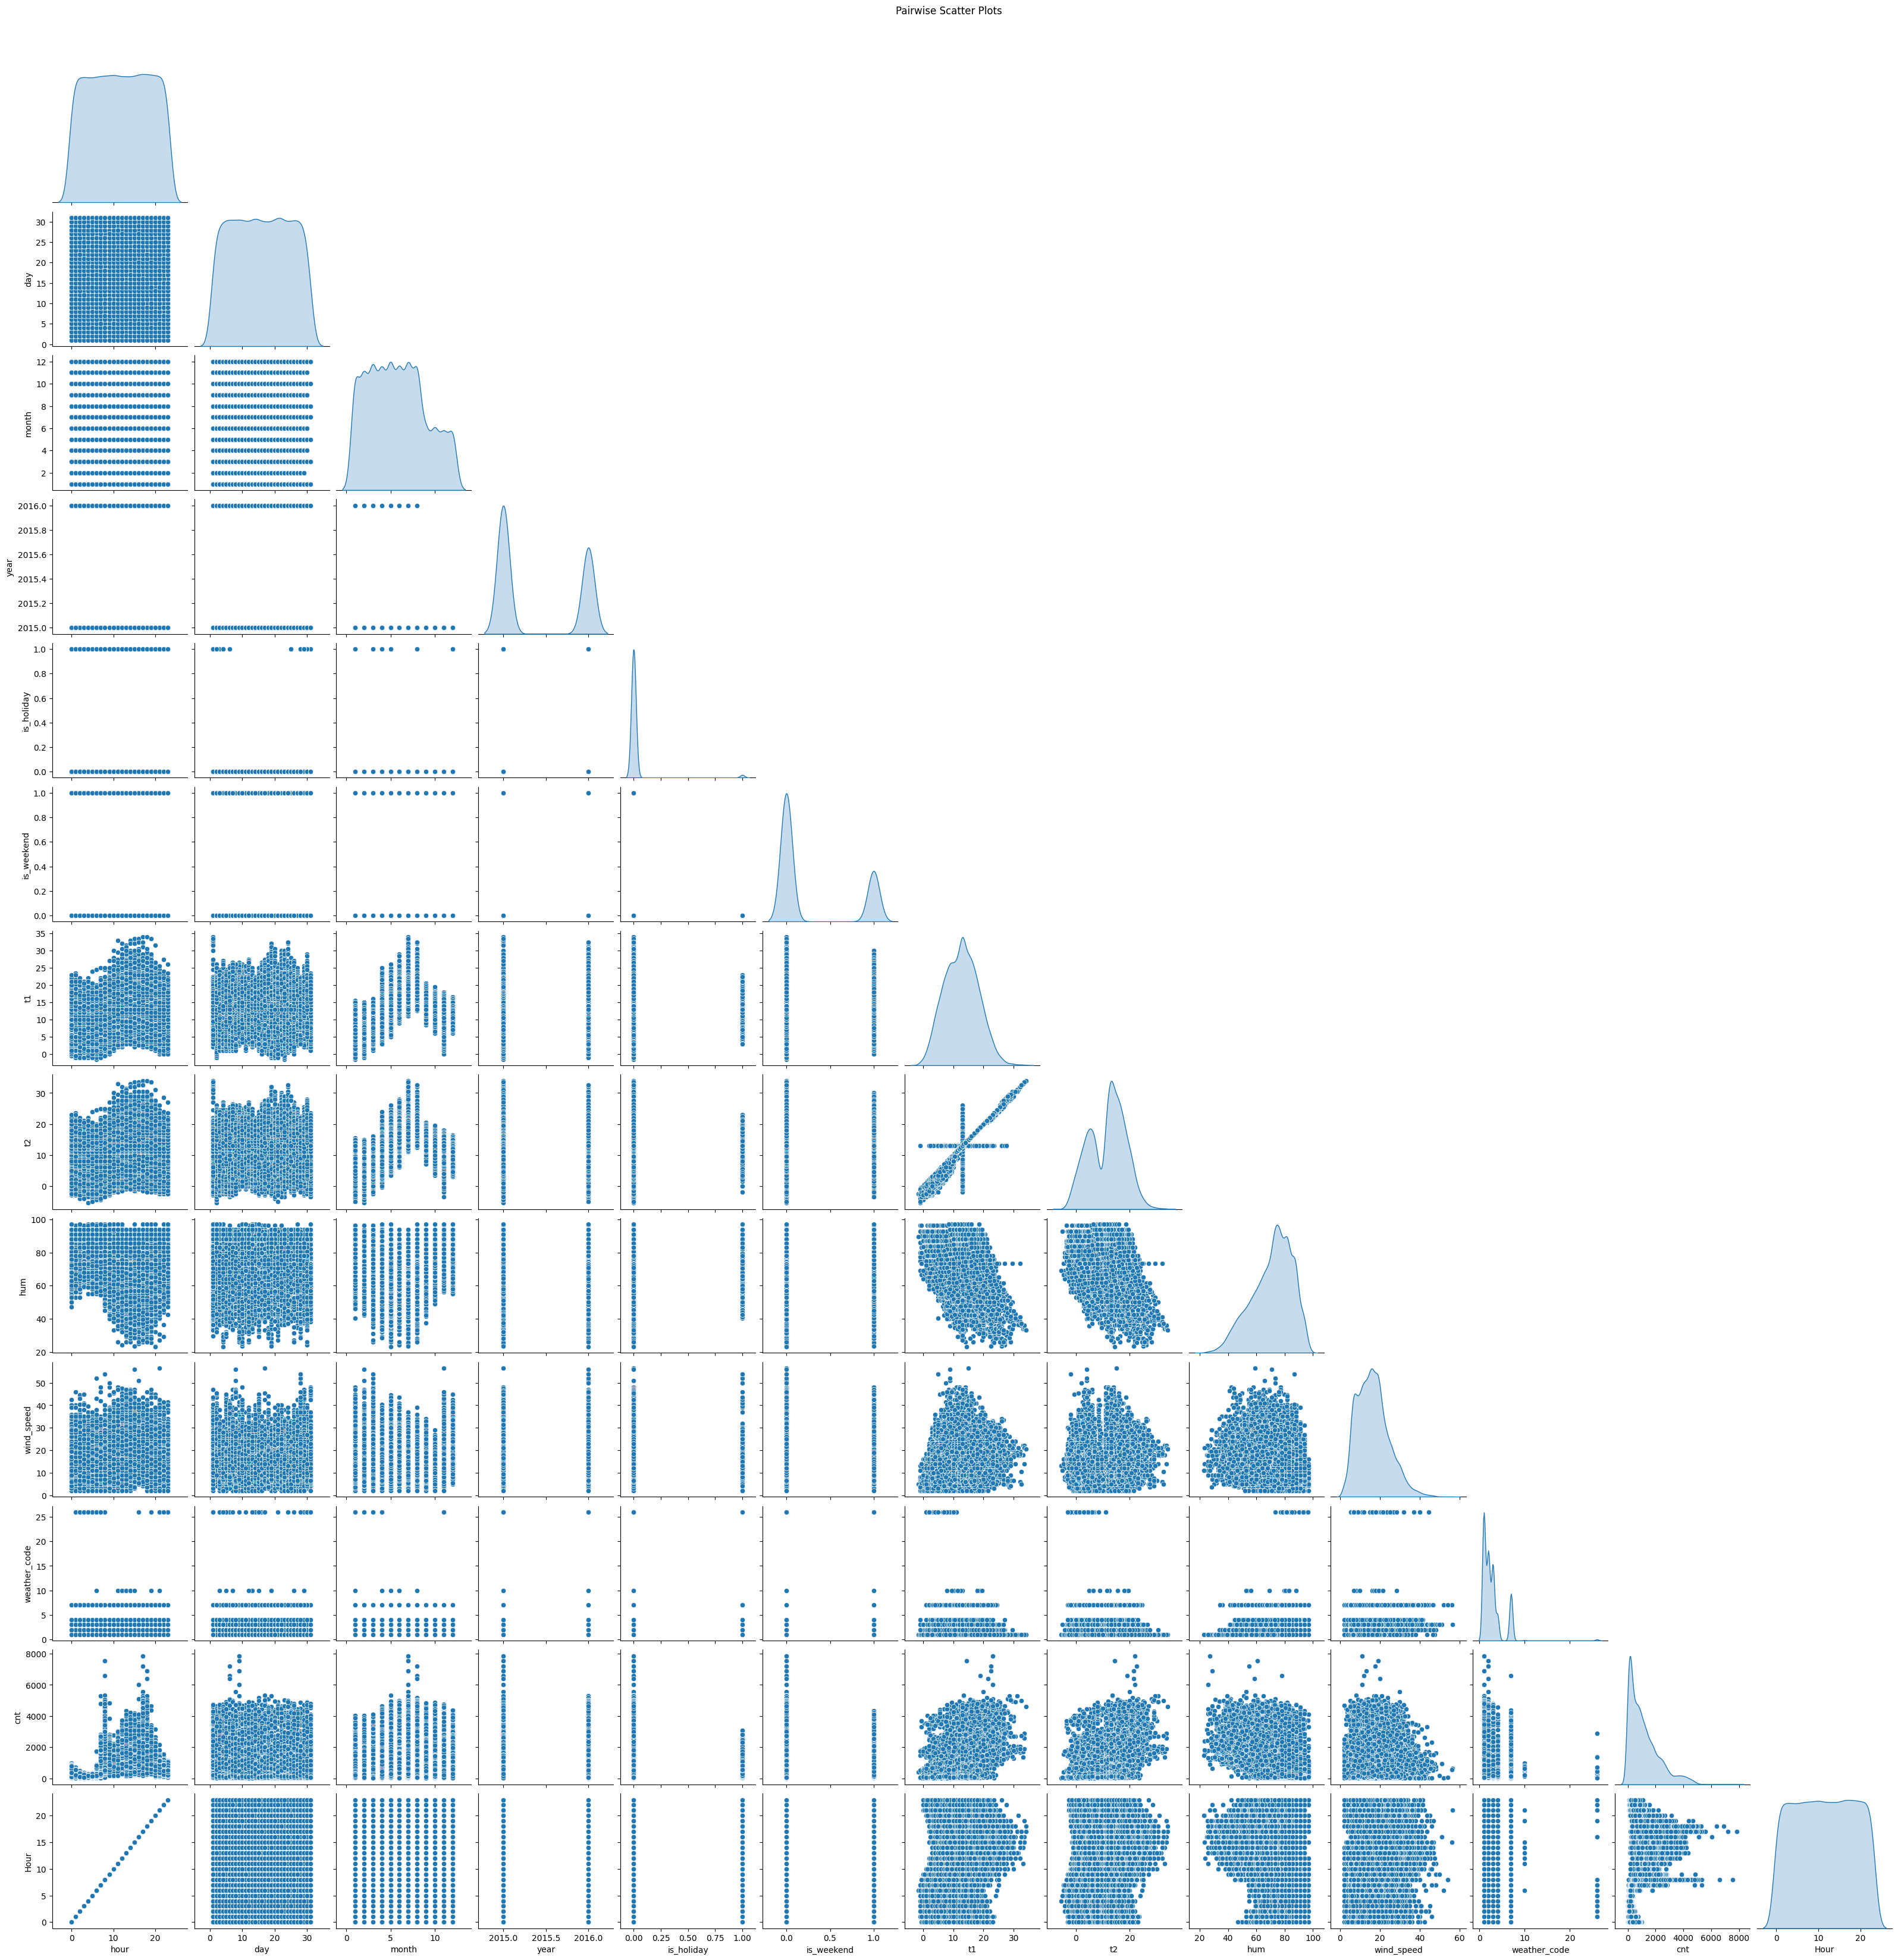


Top correlated pairs (|r| > 0.7):
hour vs Hour: r = 1.00


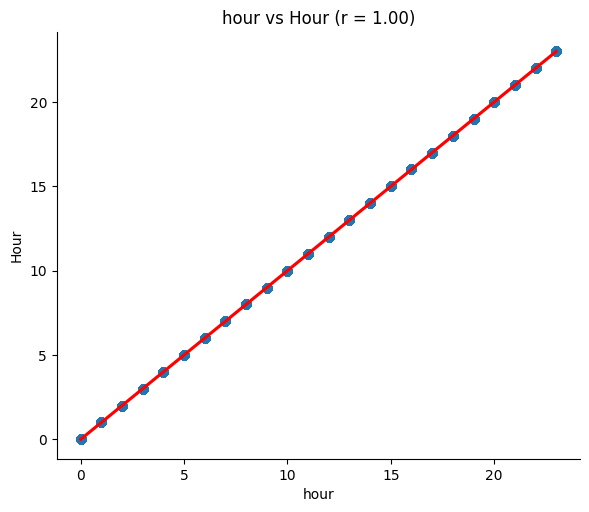

t2 vs t1: r = 0.98


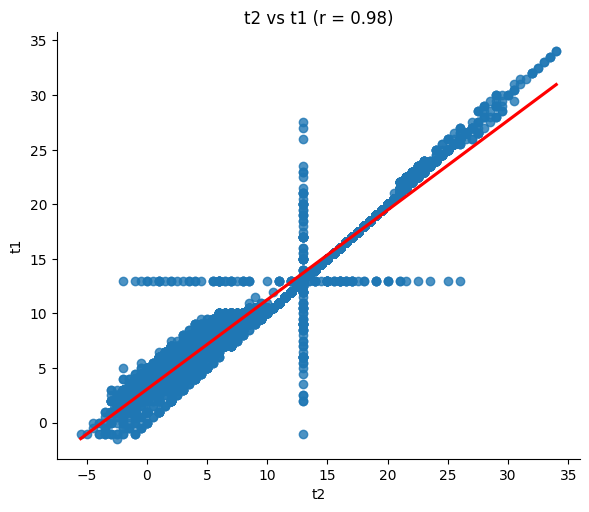

t2 vs month: r = 0.54


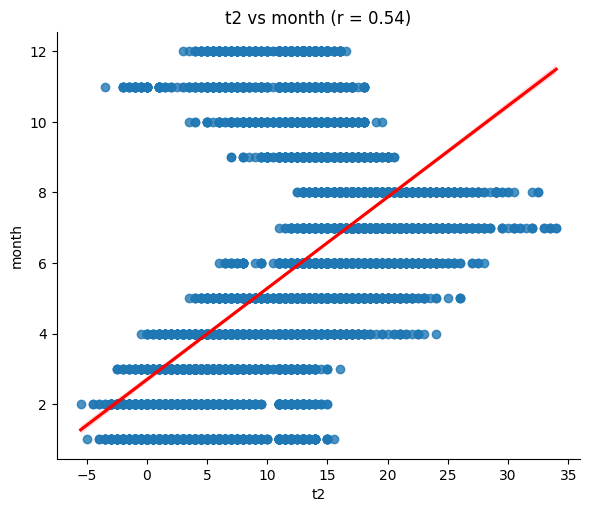

month vs t1: r = 0.51


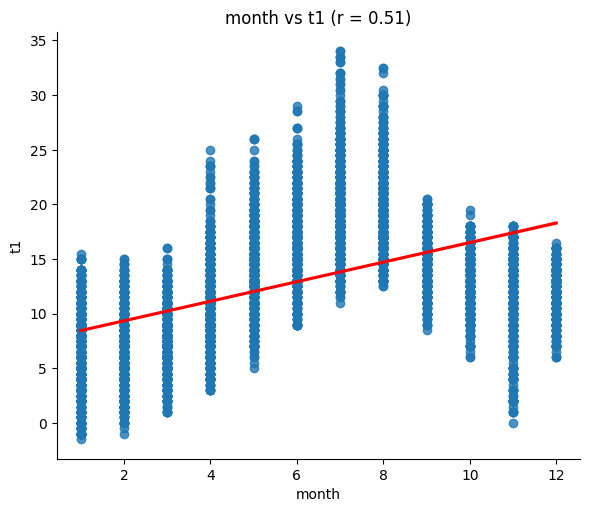

In [74]:
numeric_cols = df.select_dtypes(include='number').columns

# Correlation Matrix
corr_matrix = df[numeric_cols].corr(method='pearson')

# Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', square=True)
plt.title("Correlation Heatmap")
plt.show()

# Pairplot
sns.pairplot(df[numeric_cols], diag_kind='kde', corner=True)
plt.suptitle("Pairwise Scatter Plots", y=1.02)
plt.show()


# Optional: Regression plots for top correlations
top_corrs = corr_matrix.abs().unstack().sort_values(ascending=False)
seen = set()
print("\nTop correlated pairs (|r| > 0.7):")
for (var1, var2), corr in top_corrs.items():
    if var1 == var2 or (var2, var1) in seen:
        continue
    seen.add((var1, var2))
    if corr > 0.5:
        print(f"{var1} vs {var2}: r = {corr:.2f}")
        sns.lmplot(data=df, x=var1, y=var2, height=5, aspect=1.2, line_kws={"color": "red"})
        plt.title(f"{var1} vs {var2} (r = {corr:.2f})")
        plt.show()

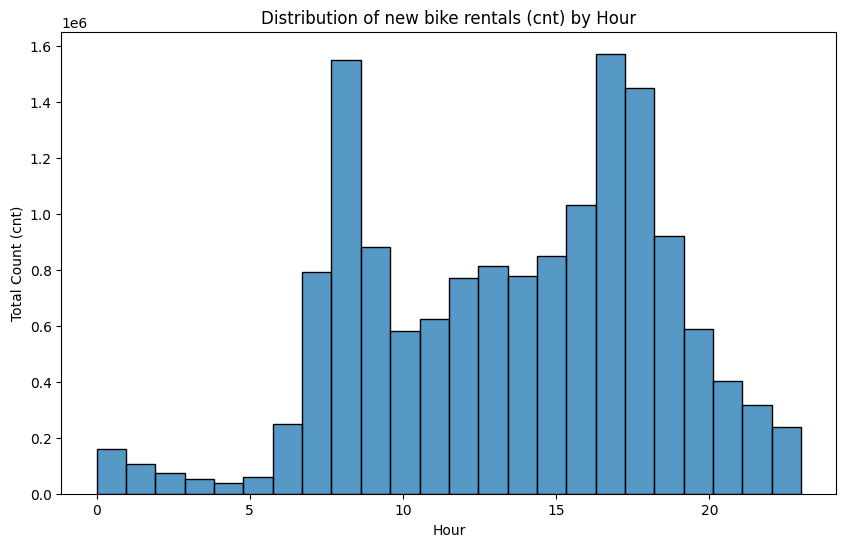

In [75]:
plt.figure(figsize=(10, 6))
sns.histplot(data=df, x='hour', weights='cnt', bins=24, kde=False)
plt.title('Distribution of new bike rentals (cnt) by Hour')
plt.xlabel('Hour')
plt.ylabel('Total Count (cnt)')
plt.show()

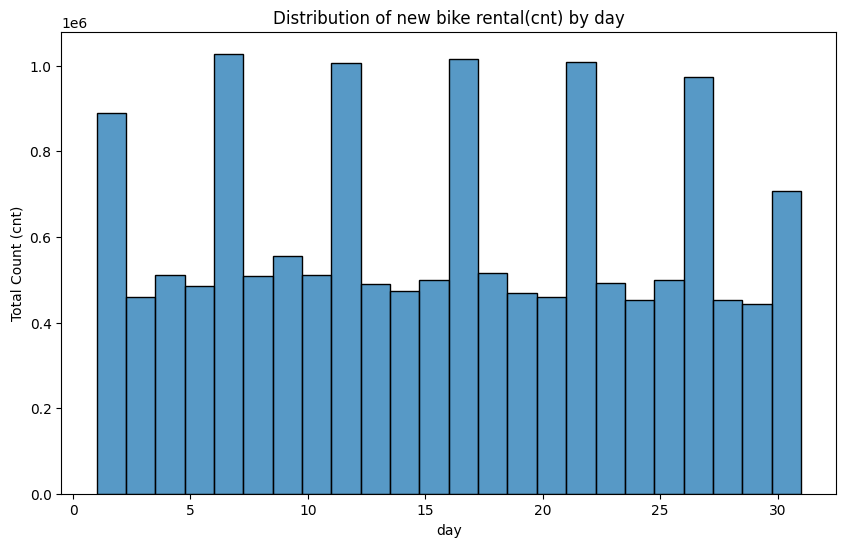

In [76]:
plt.figure(figsize=(10, 6))
sns.histplot(data=df, x='day', weights='cnt', bins=24, kde=False)
plt.title('Distribution of new bike rental(cnt) by day')
plt.xlabel('day')
plt.ylabel('Total Count (cnt)')
plt.show()

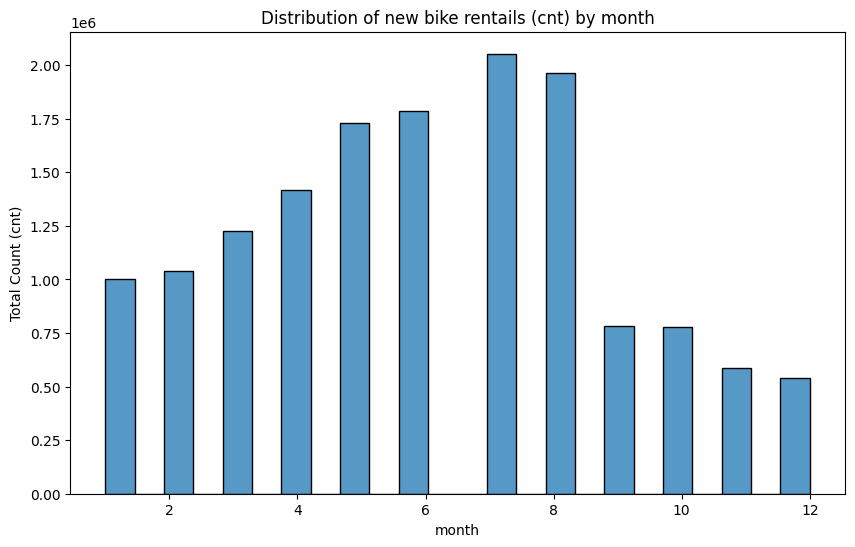

In [77]:
plt.figure(figsize=(10, 6))
sns.histplot(data=df, x='month', weights='cnt', bins=24, kde=False)
plt.title('Distribution of new bike rentails (cnt) by month')
plt.xlabel('month')
plt.ylabel('Total Count (cnt)')
plt.show()

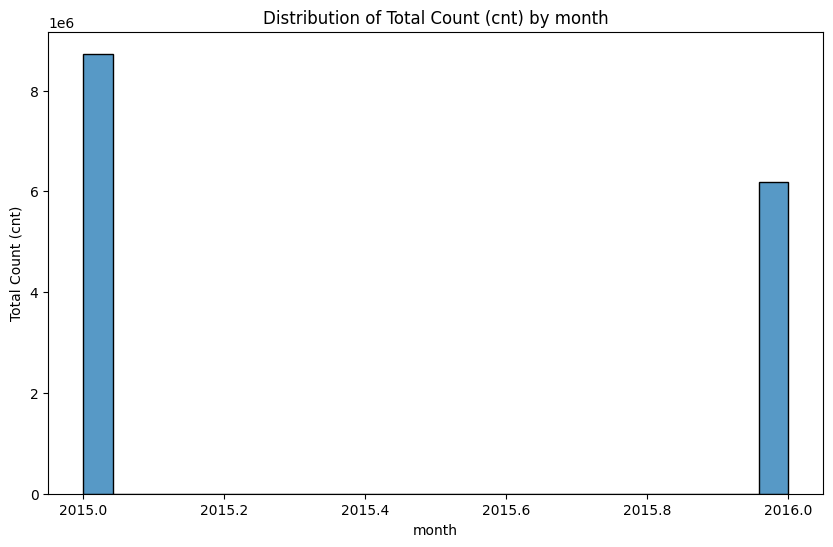

In [78]:
plt.figure(figsize=(10, 6))
sns.histplot(data=df, x='year', weights='cnt', bins=24, kde=False)
plt.title('Distribution of Total Count (cnt) by month')
plt.xlabel('month')
plt.ylabel('Total Count (cnt)')
plt.show()

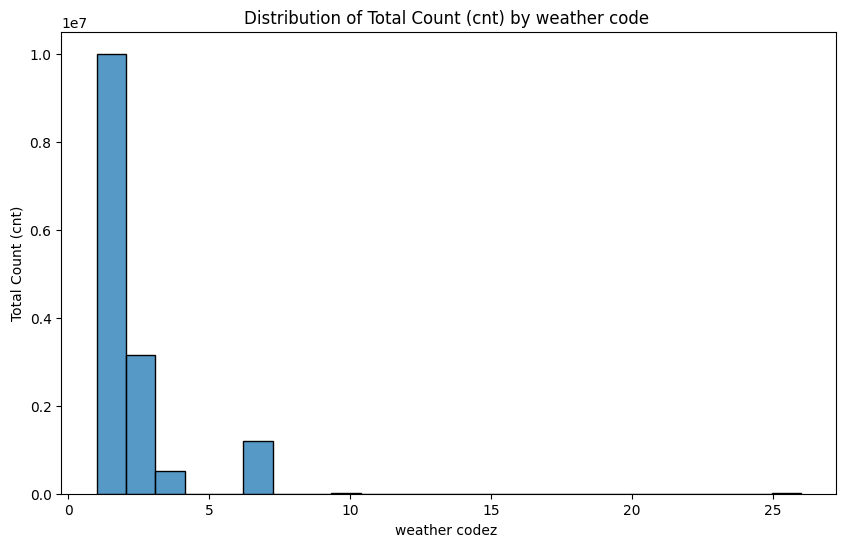

In [79]:
plt.figure(figsize=(10, 6))
sns.histplot(data=df, x='weather_code', weights='cnt', bins=24, kde=False)
plt.title('Distribution of Total Count (cnt) by weather code ')
plt.xlabel('weather codez ')
plt.ylabel('Total Count (cnt)')
plt.show()

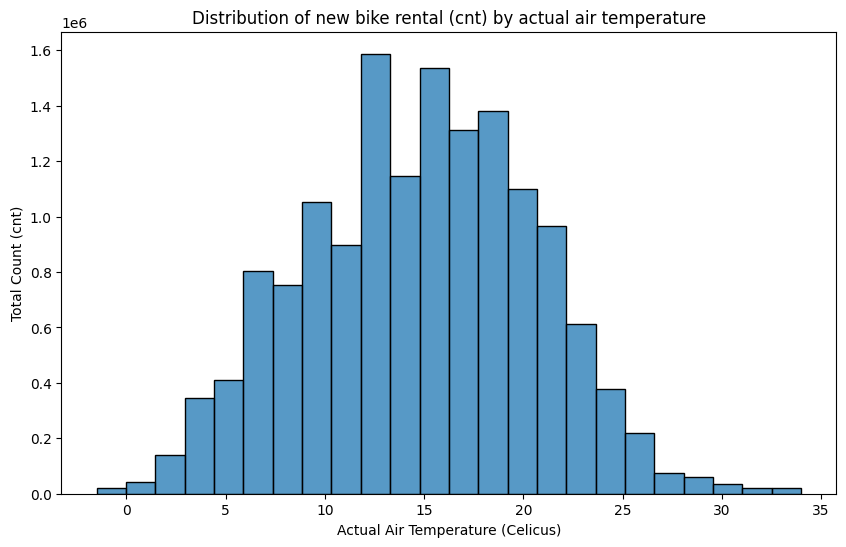

In [80]:
plt.figure(figsize=(10, 6))
sns.histplot(data=df, x='t1', weights='cnt', bins=24, kde=False)
plt.title('Distribution of new bike rental (cnt) by actual air temperature')
plt.xlabel('Actual Air Temperature (Celicus)')
plt.ylabel('Total Count (cnt)')
plt.show()

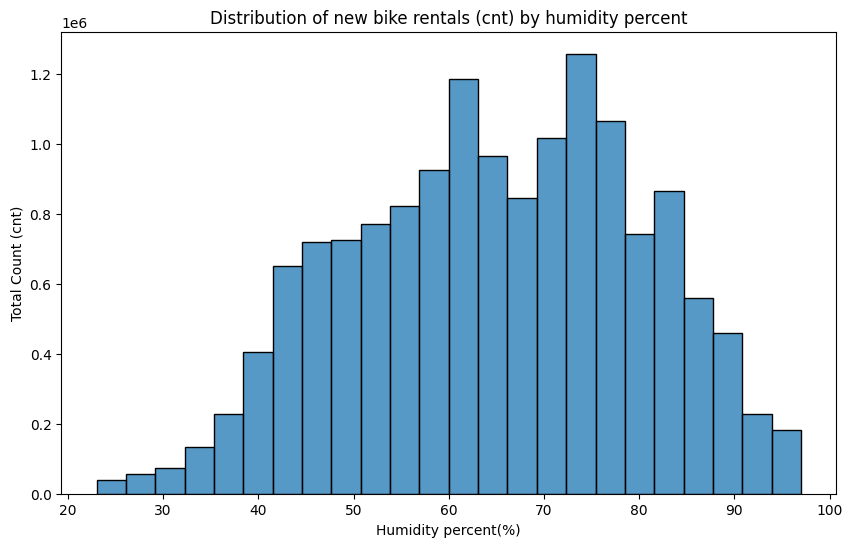

In [81]:
plt.figure(figsize=(10, 6))
sns.histplot(data=df, x='hum', weights='cnt', bins=24, kde=False)
plt.title('Distribution of new bike rentals (cnt) by humidity percent')
plt.xlabel('Humidity percent(%)')
plt.ylabel('Total Count (cnt)')
plt.show()

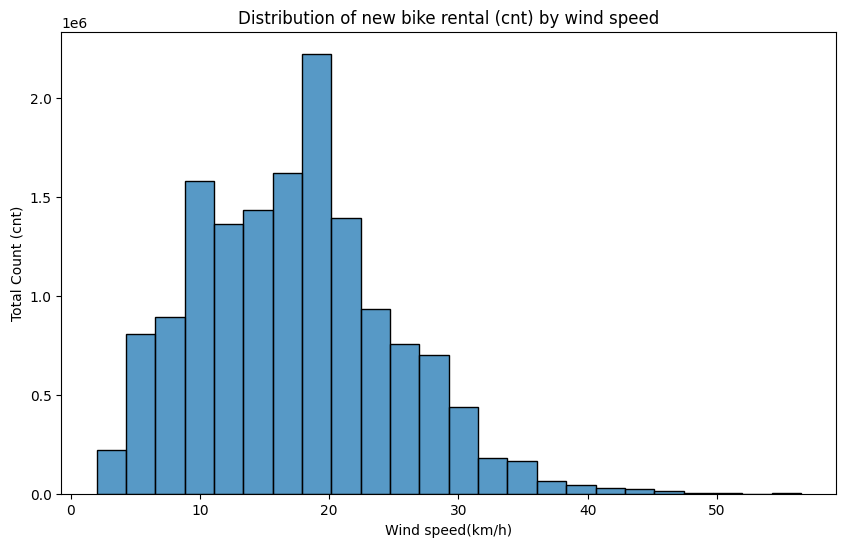

In [82]:
plt.figure(figsize=(10, 6))
sns.histplot(data=df, x='wind_speed', weights='cnt', bins=24, kde=False)
plt.title('Distribution of new bike rental (cnt) by wind speed')
plt.xlabel('Wind speed(km/h)')
plt.ylabel('Total Count (cnt)')
plt.show()

## Numerical vs categorical data

In [83]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 12927 entries, 0 to 14452
Data columns (total 16 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   timestamp     12927 non-null  datetime64[ns]
 1   hour          12927 non-null  int64         
 2   day           12927 non-null  int64         
 3   month         12927 non-null  int64         
 4   year          12927 non-null  int64         
 5   is_holiday    12927 non-null  float64       
 6   is_weekend    12927 non-null  float64       
 7   season        12927 non-null  category      
 8   t1            12927 non-null  float64       
 9   t2            12927 non-null  float64       
 10  hum           12927 non-null  float64       
 11  wind_speed    12927 non-null  float64       
 12  weather_code  12927 non-null  float64       
 13  cnt           12927 non-null  float64       
 14  Hour          12927 non-null  int32         
 15  TimeOfDay     12927 non-null  category   

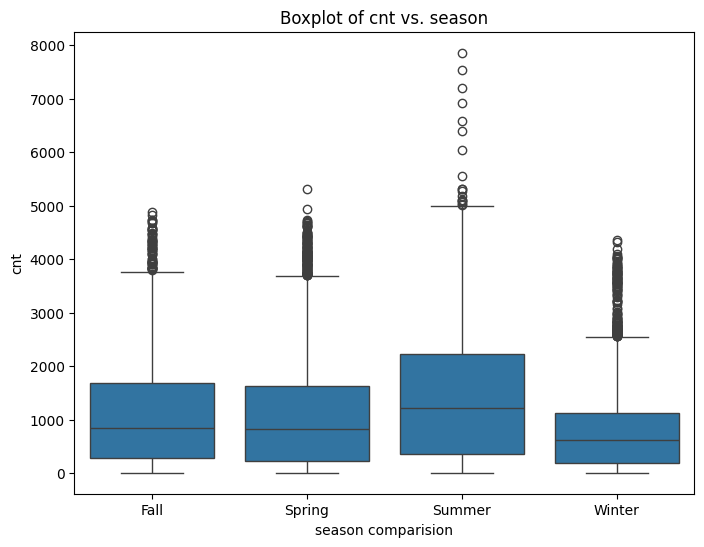

In [84]:
# Create boxplots for cnt, t1, hum, wind speed against season
import matplotlib.pyplot as plt
import seaborn as sns

# Assuming 'df' is your DataFrame and it has the columns mentioned
# Numerical features to plot
numerical_features = ['cnt']

# Loop through numerical features and create boxplots
for feature in numerical_features:
    plt.figure(figsize=(8, 6))  # Adjust figure size if needed
    sns.boxplot(x='season', y=feature, data=df)
    plt.title(f'Boxplot of {feature} vs. season')
    plt.xlabel('season comparision')
    plt.ylabel(feature)
    plt.show()

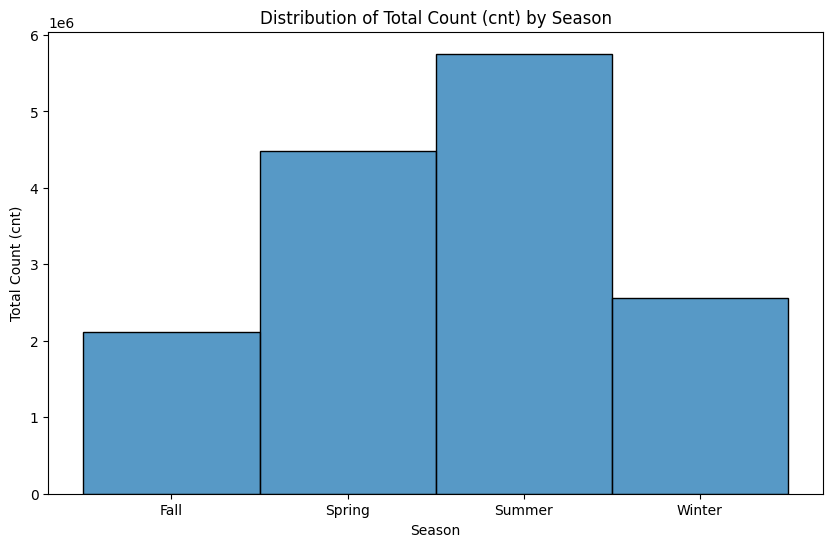

In [85]:
plt.figure(figsize=(10, 6))
sns.histplot(data=df, x='season', weights='cnt', kde=False)
plt.title('Distribution of Total Count (cnt) by Season')
plt.xlabel('Season')
plt.ylabel('Total Count (cnt)')
plt.show()

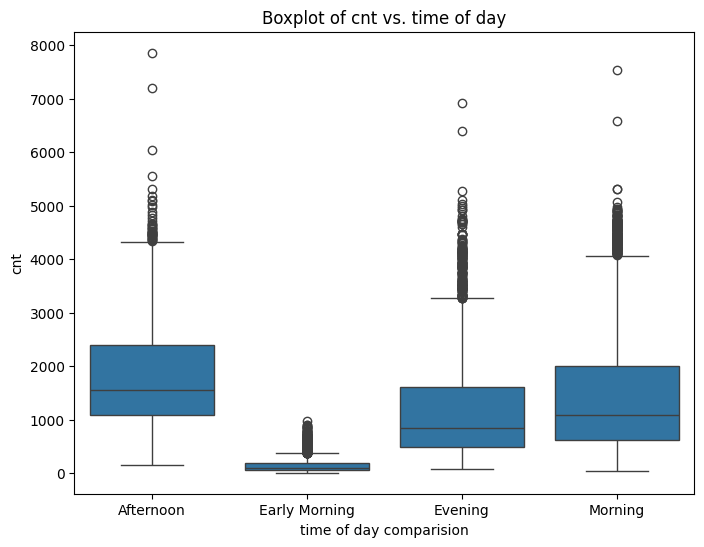

In [86]:
# Create boxplots for cnt, t1, hum, wind speed against timeofday
import matplotlib.pyplot as plt
import seaborn as sns

# Assuming 'df' is your DataFrame and it has the columns mentioned
# Numerical features to plot
numerical_features = ['cnt']

# Loop through numerical features and create boxplots
for feature in numerical_features:
    plt.figure(figsize=(8, 6))  # Adjust figure size if needed
    sns.boxplot(x='TimeOfDay', y=feature, data=df)
    plt.title(f'Boxplot of {feature} vs. time of day')
    plt.xlabel('time of day comparision')
    plt.ylabel(feature)
    plt.show()

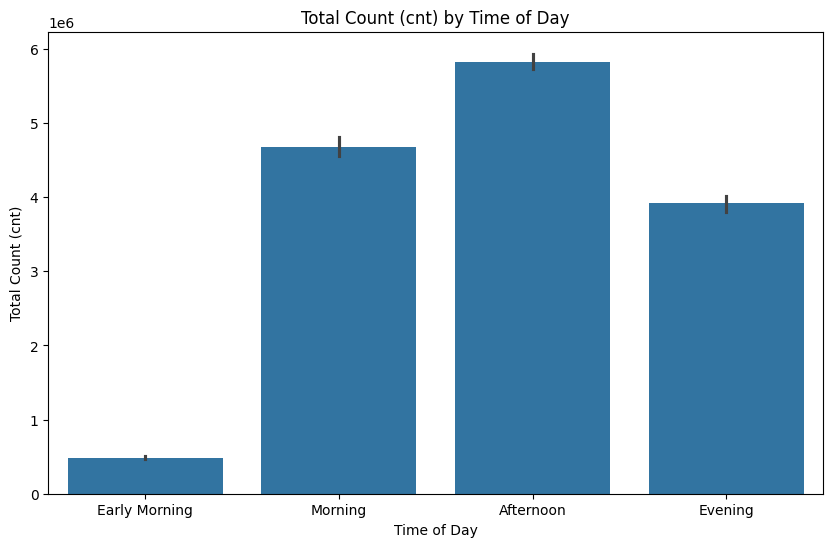

In [87]:
plt.figure(figsize=(10, 6))
time_of_day_order = ['Early Morning', 'Morning', 'Afternoon', 'Evening']
sns.barplot(data=df, x='TimeOfDay', y='cnt', estimator=sum, order=time_of_day_order)
plt.title('Total Count (cnt) by Time of Day')
plt.xlabel('Time of Day')
plt.ylabel('Total Count (cnt)')
plt.show()

#Multivariate Analysis

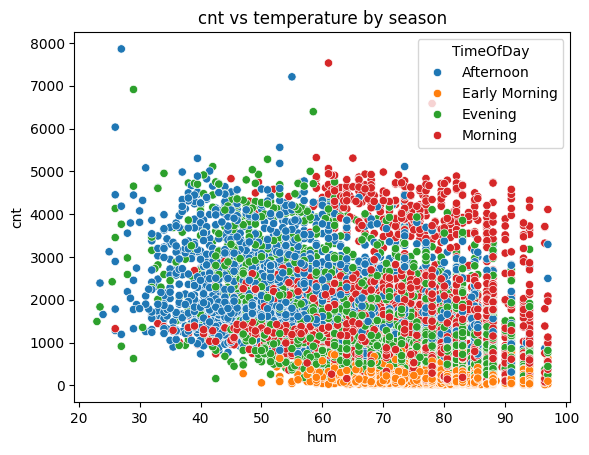

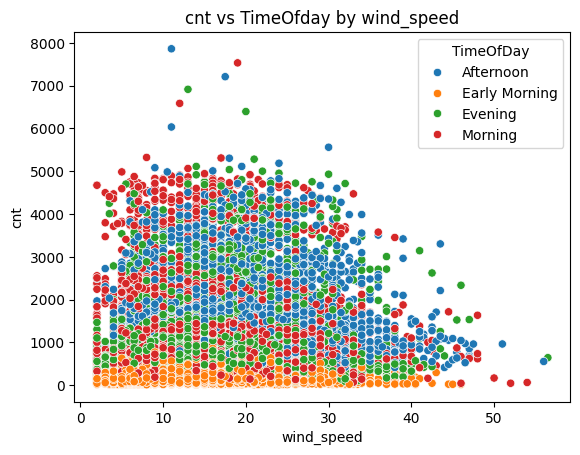

In [88]:
sns.scatterplot(data=df, x='hum', y='cnt', hue='TimeOfDay')
plt.title("cnt vs temperature by season")
plt.show()

sns.scatterplot(data=df, x='wind_speed', y='cnt', hue='TimeOfDay')
plt.title("cnt vs TimeOfday by wind_speed")
plt.show()

# Linear regression

## Further pre-processing

In [89]:
# Sample dataset with nominal categories
df_nominal = pd.DataFrame({'season': ['Spring', 'Summer', 'Fall', 'Winter']})

# Apply One-Hot Encoding
df_encoded = pd.get_dummies(df_nominal, columns=['season'])

print(df_encoded)

   season_Fall  season_Spring  season_Summer  season_Winter
0        False           True          False          False
1        False          False           True          False
2         True          False          False          False
3        False          False          False           True


In [90]:
df_one_hot_drop_first = pd.get_dummies(df_nominal, columns=['season'], drop_first=True)
print(df_one_hot_drop_first)

   season_Spring  season_Summer  season_Winter
0           True          False          False
1          False           True          False
2          False          False          False
3          False          False           True


In [91]:
# Sample dataset with nominal categories
df_nominal = pd.DataFrame({'TimeOfDay': ['Early Morning', 'Morning', 'Evening', 'Afternoon']})

# Apply One-Hot Encoding
df_encoded = pd.get_dummies(df_nominal, columns=['TimeOfDay'])

print(df_encoded)

   TimeOfDay_Afternoon  TimeOfDay_Early Morning  TimeOfDay_Evening  \
0                False                     True              False   
1                False                    False              False   
2                False                    False               True   
3                 True                    False              False   

   TimeOfDay_Morning  
0              False  
1               True  
2              False  
3              False  


In [92]:
df_one_hot_drop_first = pd.get_dummies(df_nominal, columns=['TimeOfDay'], drop_first=True)
print(df_one_hot_drop_first)

   TimeOfDay_Early Morning  TimeOfDay_Evening  TimeOfDay_Morning
0                     True              False              False
1                    False              False               True
2                    False               True              False
3                    False              False              False


In [93]:
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score,  mean_absolute_error

In [94]:
# Select features and target

#X = df.drop(['cnt','timestamp','season','TimeOfDay'], axis=1)
#y = df['cnt']

In [95]:
# Selection feature again
features = ['hour', 't1', 't2', 'hum', 'wind_speed']
X = df[features]
y = df['cnt']

##Data partitioning

In [96]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=200)

##Feature selection

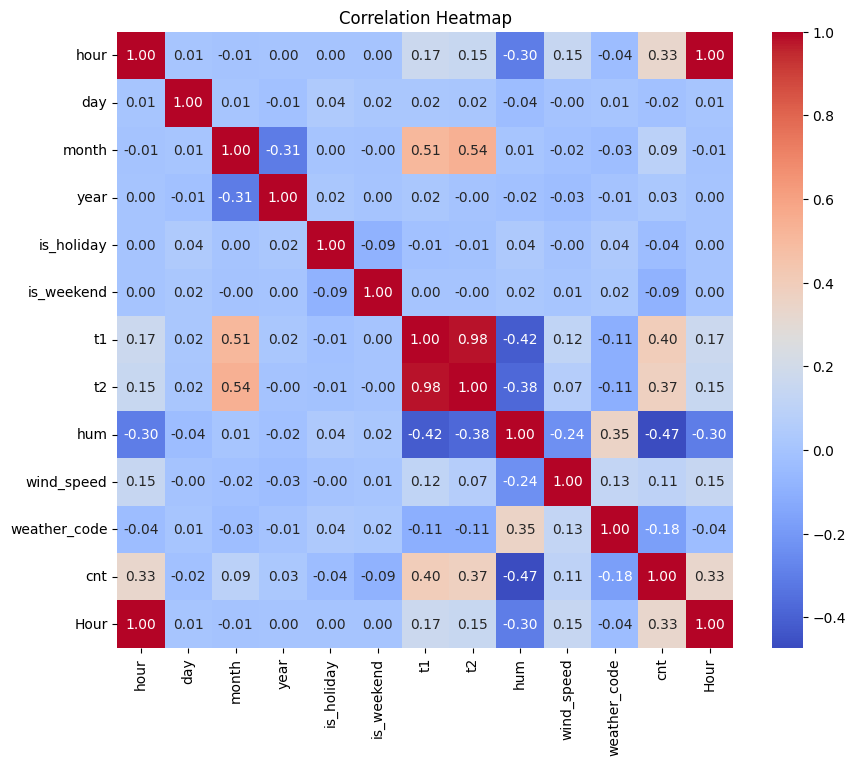

In [97]:
# Correlation Matrix
corr_matrix = df[numeric_cols].corr(method='pearson')
# Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', square=True)
plt.title("Correlation Heatmap")
plt.show()

In [98]:
from sklearn.feature_selection import VarianceThreshold

# Initialize VarianceThreshold
# You can set a threshold for the variance (e.g., 0 for removing features with zero variance)
# A common practice is to remove features with very low variance.
selector = VarianceThreshold(threshold=0.1) # Adjust the threshold as needed

# Fit on the training data
selector.fit(X_train)

# Get the indices of the selected features
selected_features_indices = selector.get_support(indices=True)

# Get the names of the selected features
selected_features = X_train.columns[selected_features_indices]

# Transform both the training and testing sets to include only the selected features
X_train_selected = selector.transform(X_train)
X_test_selected = selector.transform(X_test)

# Convert the transformed arrays back to DataFrames with the selected column names
X_train = pd.DataFrame(X_train_selected, columns=selected_features)
X_test = pd.DataFrame(X_test_selected, columns=selected_features)

print("Original number of features:", X.shape[1])
print("Number of selected features:", X_train.shape[1])
print("Selected features:", selected_features.tolist())

Original number of features: 5
Number of selected features: 5
Selected features: ['hour', 't1', 't2', 'hum', 'wind_speed']


In [99]:
from sklearn.linear_model import LassoCV
from sklearn.feature_selection import SelectFromModel

# Initialize LassoCV (Lasso with cross-validation to find the best alpha)
# You can adjust the number of cross-validation folds (cv) and other parameters
lasso = LassoCV(cv=5, random_state=2024)

# Fit the Lasso model to the training data
lasso.fit(X_train, y_train)

# Use SelectFromModel to select features based on the fitted Lasso model
# The threshold can be 'median', 'mean', a specific value, or None (uses 1e-5 by default)
model_selector = SelectFromModel(lasso, prefit=True, threshold='median')

# Transform both the training and testing sets to include only the selected features
X_train_selected = model_selector.transform(X_train)
X_test_selected = model_selector.transform(X_test)

# Get the names of the selected features
selected_features_mask = model_selector.get_support()
selected_features = X_train.columns[selected_features_mask]

# Convert the transformed arrays back to DataFrames with the selected column names
X_train = pd.DataFrame(X_train_selected, columns=selected_features)
X_test = pd.DataFrame(X_test_selected, columns=selected_features)


print("Original number of features:", X.shape[1])
print("Number of selected features:", X_train.shape[1])
print("Selected features:", selected_features.tolist())

Original number of features: 5
Number of selected features: 3
Selected features: ['hour', 't1', 'hum']


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but SelectFromModel was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but SelectFromModel was fitted without feature names
  warnings.warn(


In [100]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_selection import SelectFromModel

# Initialize a tree-based model (RandomForestRegressor is a good choice)
# You can adjust parameters like n_estimators, random_state, etc.
tree_based_model = RandomForestRegressor(n_estimators=100, random_state=2024)

# Fit the model to the training data to calculate feature importances
tree_based_model.fit(X_train, y_train)

# Use SelectFromModel to select features based on feature importances
# The threshold can be 'median', 'mean', a specific value, or None (uses 1e-5 by default)
model_selector = SelectFromModel(tree_based_model, prefit=True, threshold='median') # Adjust threshold as needed

# Transform both the training and testing sets to include only the selected features
X_train_selected = model_selector.transform(X_train)
X_test_selected = model_selector.transform(X_test)

# Get the names of the selected features
selected_features_mask = model_selector.get_support()
selected_features = X_train.columns[selected_features_mask]

# Convert the transformed arrays back to DataFrames with the selected column names
X_train = pd.DataFrame(X_train_selected, columns=selected_features)
X_test = pd.DataFrame(X_test_selected, columns=selected_features)

print("Original number of features:", X.shape[1])
print("Number of selected features:", X_train.shape[1])
print("Selected features:", selected_features.tolist())

Original number of features: 5
Number of selected features: 2
Selected features: ['hour', 't1']


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but SelectFromModel was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but SelectFromModel was fitted without feature names
  warnings.warn(


##Model training

In [101]:
# Initialise and train the linear regression model
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

##Model performance evaluation

In [102]:
# Make predictions on the test set
y_pred = model.predict(X_test)

In [103]:
# Create a dictionary for the results
results_data = {
    'Actual_cnt': y_test.values[:20],
    'Predicted_cnt': y_pred[:20]
}

# Add the selected features from X_test to the results dictionary
# We take the first 20 rows to match the actual and predicted values
for col in X_test.columns:
    results_data[col] = X_test[col].values[:20]

# Create the results DataFrame from the dictionary
df_results = pd.DataFrame(results_data)

# Display the results against the actual records
display(df_results)

,Actual_cnt,Predicted_cnt,hour,t1
0,1991.00,1430.02,16.00,14.00
1,286.00,1314.37,23.00,8.00
2,2449.00,769.50,7.00,10.00
3,386.00,1315.93,2.00,21.00
4,1254.00,1527.44,11.00,18.50
5,491.00,1548.00,22.00,12.00
6,1839.00,2299.73,21.00,23.50
7,1247.00,1281.77,19.00,10.00
8,100.00,934.05,6.00,13.00
9,587.00,519.57,6.00,7.00


In [104]:
# Calculate Absolute Mean Error (MAE)
mae = mean_absolute_error(y_test, y_pred)

# Calculate Mean Squared Error (MSE)
mse = mean_squared_error(y_test, y_pred)

# Calculate Root Mean Squared Error (RMSE)
rmse = np.sqrt(mse)

# Calculate R2
r2 = r2_score(y_test, y_pred)

In [105]:
print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Mean Squared Error: {mse:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"R-squared: {r2:.2f}")

Mean Absolute Error (MAE): 703.02
Mean Squared Error: 935982.34
Root Mean Squared Error (RMSE): 967.46
R-squared: 0.22


In [106]:
y_test.describe()

,cnt
count,2586.00
mean,1177.99
std,1095.01
min,11.00
25%,285.25
50%,894.00
75%,1713.00
max,6913.00


In [107]:
combined_desc = pd.DataFrame({
    'Pred': pd.Series(y_pred).describe(),
    'Test': y_test.describe()
})
combined_desc

,Pred,Test
count,2586.00,2586.00
mean,1151.88,1177.99
std,523.89,1095.01
min,-246.52,11.00
25%,779.59,285.25
50%,1141.29,894.00
75%,1525.49,1713.00
max,2897.01,6913.00


## Model specification

In [108]:
# Print feature names and coefficients
coeff_df = pd.DataFrame({
    'features': X_train.columns,
    'Coefficient': model.coef_
})
print(coeff_df)

  features  Coefficient
0     hour        42.69
1       t1        69.08


In [109]:
# Print intercept
print("Intercept:", model.intercept_)

Intercept: -220.13326051625882


## Detect multi colinearity

In [110]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

# get the data for the features
vif_data = pd.DataFrame()
vif_data['feature'] = X.columns

# Calculate VIF for each feature
vif_data['VIF'] = [variance_inflation_factor(X.values, i) for i in range(len(X.columns))]

vif_data

,feature,VIF
0,hour,1.11
1,t1,27.59
2,t2,26.51
3,hum,1.37
4,wind_speed,1.12


In [111]:
def calculate_vif(data):
    """Calculate VIF for each feature in the DataFrame."""
    vif_df = pd.DataFrame()
    vif_df['Feature'] = data.columns
    vif_df['VIF'] = [variance_inflation_factor(data.values, i) for i in range(data.shape[1])]
    return vif_df

# Set the VIF threshold; here we use 10 as an example
vif_threshold = 10

# Iteratively remove features with high VIF
while True:
    vif_df = calculate_vif(X)
    max_vif = vif_df['VIF'].max()
    if max_vif > vif_threshold:
        # Identify the feature with the highest VIF
        feature_to_drop = vif_df.loc[vif_df['VIF'] == max_vif, 'Feature'].values[0]
        print(f"Dropping {feature_to_drop} with VIF: {max_vif:.2f}")
        X = X.drop(columns=[feature_to_drop])
    else:
        break

print("Final features after VIF reduction:")
print(X.columns)
print("\nFinal VIF values:")
print(calculate_vif(X))

Dropping t1 with VIF: 27.59
Final features after VIF reduction:
Index(['hour', 't2', 'hum', 'wind_speed'], dtype='object')

Final VIF values:
      Feature  VIF
0        hour 1.11
1          t2 1.17
2         hum 1.31
3  wind_speed 1.07


#Decision Regressor

In [112]:
#import libraries and functions

import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, r2_score,  mean_absolute_error, root_mean_squared_error

In [113]:
# List of categorical columns to encode
cat_cols = ['season', 'TimeOfDay']

# Dictionary to store mappings (optional but useful for decoding later)
category_mappings = {}

# Loop through each column and apply category encoding
for col in cat_cols:
    df[col] = df[col].astype('category')  # convert to categorical
    df[col + '_Code'] = df[col].cat.codes  # store codes in new column
    category_mappings[col] = dict(enumerate(df[col].cat.categories))  # store mapping

In [114]:
# Select features  and target
X = df.drop(columns=['timestamp', 'year', 'cnt'] +cat_cols)
y = df['cnt']

In [115]:
# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=2025)

In [116]:
dt = DecisionTreeRegressor(random_state=250)
dt.fit(X_train, y_train)

DecisionTreeRegressor(random_state=250)

In [117]:
# Make predictions on the test set
y_pred_train = dt.predict(X_train)

# Calculate Absolute Mean Error (MAE)
mae = mean_absolute_error(y_train, y_pred_train)

# Calculate Mean Squared Error (MSE)
mse = mean_squared_error(y_train, y_pred_train)

# Calculate Root Mean Squared Error (RMSE)
rmse = root_mean_squared_error(y_train, y_pred_train)

# Calculate R2
r2 = r2_score(y_train, y_pred_train)

print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Mean Squared Error: {mse:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"R-squared: {r2:.2f}")

Mean Absolute Error (MAE): 0.00
Mean Squared Error: 0.00
Root Mean Squared Error (RMSE): 0.00
R-squared: 1.00


In [118]:
# Make predictions on the test set
y_pred = dt.predict(X_test)

In [119]:
# Calculate Absolute Mean Error (MAE)
mae = mean_absolute_error(y_test, y_pred)

# Calculate Mean Squared Error (MSE)
mse = mean_squared_error(y_test, y_pred)

# Calculate Root Mean Squared Error (RMSE)
rmse = root_mean_squared_error(y_test, y_pred)

# Calculate R2
r2 = r2_score(y_test, y_pred)

In [120]:
print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Mean Squared Error: {mse:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"R-squared: {r2:.2f}")

Mean Absolute Error (MAE): 182.04
Mean Squared Error: 110933.48
Root Mean Squared Error (RMSE): 333.07
R-squared: 0.90


# Better decision tree regressor?

## Pre Prune DT

In [121]:
# Initialise pre-pruned Decision Tree Regressor
pre_pruned_dt = DecisionTreeRegressor(
    max_depth=100,
    max_features='sqrt',
    criterion='squared_error',
    splitter='best',
    min_samples_split=10,
    random_state=2024
)

# Train the model
pre_pruned_dt = pre_pruned_dt.fit(X_train, y_train)

# Predict on test set
y_pred_pre_pruned = pre_pruned_dt.predict(X_test)

In [122]:
# Calculate Absolute Mean Error (MAE)
mae = mean_absolute_error(y_test, y_pred_pre_pruned)

# Calculate Mean Squared Error (MSE)
mse = mean_squared_error(y_test, y_pred_pre_pruned)

# Calculate Root Mean Squared Error (RMSE)
rmse = root_mean_squared_error(y_test, y_pred_pre_pruned)

# Calculate R2
r2 = r2_score(y_test, y_pred_pre_pruned)

print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Mean Squared Error: {mse:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"R-squared: {r2:.4f}")

Mean Absolute Error (MAE): 252.16
Mean Squared Error: 232230.49
Root Mean Squared Error (RMSE): 481.90
R-squared: 0.7986


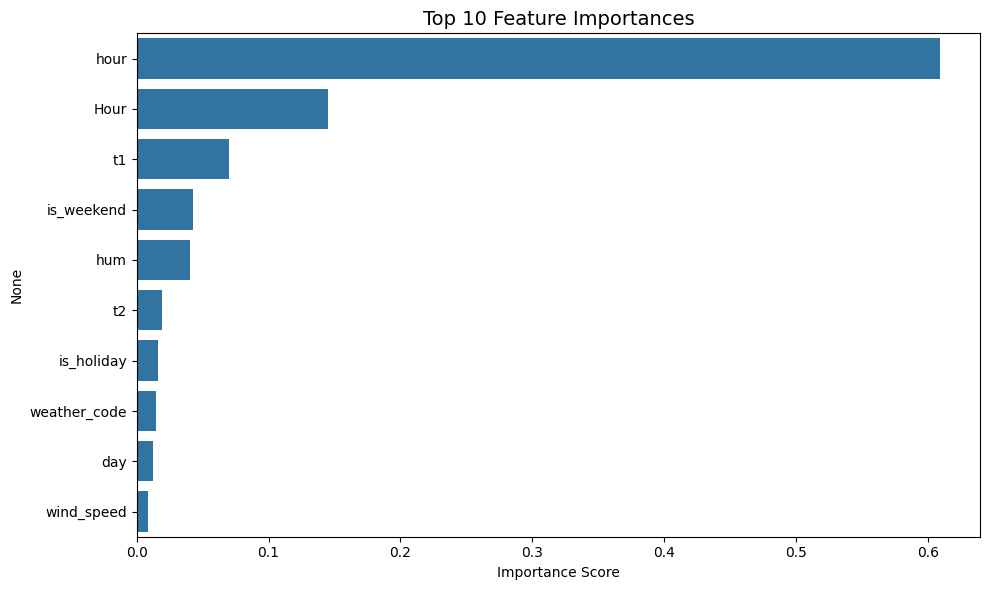

In [123]:
import pandas as pd
import seaborn as sns

importances = pd.Series(dt.feature_importances_, index=X.columns)
top_features = importances.sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_features.values, y=top_features.index)
plt.title("Top 10 Feature Importances", fontsize=14)
plt.xlabel("Importance Score")
plt.tight_layout()
plt.show()

## Post Prune DT

In [124]:
# Train full tree (no depth/min split limits)
dt_full = DecisionTreeRegressor(random_state=200)
dt_full.fit(X_train, y_train)

# Get effective alphas and impurities for pruning
path = dt_full.cost_complexity_pruning_path(X_train, y_train)
# Keep only unique and rounded alphas
ccp_alphas = path.ccp_alphas

# Sample evenly across the alpha range (e.g., 50–100 points)
ccp_alphas_sampled = np.linspace(ccp_alphas.min(), ccp_alphas.max(), num=500)
impurities = path.impurities

In [ ]:
from joblib import Parallel, delayed

def train_model(alpha):
    model = DecisionTreeRegressor(random_state=2024, ccp_alpha=alpha)
    model.fit(X_train, y_train)
    return model

# Train in parallel
models = Parallel(n_jobs=-1)(delayed(train_model)(alpha) for alpha in ccp_alphas_sampled)

In [ ]:
r2_scores = []
rmse_scores = []

for model in models:
    y_pred = model.predict(X_test)
    r2 = r2_score(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))

    r2_scores.append(r2)
    rmse_scores.append(rmse)

# Find the best model by R²
best_index = np.argmax(r2_scores)
post_pruned_dt = models[best_index]
best_alpha = ccp_alphas_sampled[best_index]
print(f'Best ccp alpha at: {best_alpha}')

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Combine metrics into a DataFrame
df_perf = pd.DataFrame({
    'ccp_alpha': ccp_alphas_sampled,
    'R2': r2_scores,
    'RMSE': rmse_scores
})

# Identify best models
best_r2_idx = df_perf['R2'].idxmax()
best_rmse_idx = df_perf['RMSE'].idxmin()

# Plot
fig, ax1 = plt.subplots(figsize=(12, 6))

# R² line (left y-axis)
sns.lineplot(data=df_perf, x='ccp_alpha', y='R2', ax=ax1, marker='o', color='tab:blue', label='R²')
ax1.set_ylabel("R²", color='tab:blue', fontsize=12)
ax1.tick_params(axis='y', labelcolor='tab:blue')
ax1.set_xlabel("ccp_alpha", fontsize=12)
ax1.grid(True, linestyle='--', linewidth=0.5)

# Highlight best R²
ax1.scatter(
    df_perf.loc[best_r2_idx, 'ccp_alpha'], df_perf.loc[best_r2_idx, 'R2'],
    color='blue', edgecolor='black', s=60, zorder=5, label='Best R²'
)

# RMSE line (right y-axis)
ax2 = ax1.twinx()
sns.lineplot(data=df_perf, x='ccp_alpha', y='RMSE', ax=ax2, marker='s', color='tab:red', label='RMSE')
ax2.set_ylabel("RMSE", color='tab:red', fontsize=12)
ax2.tick_params(axis='y', labelcolor='tab:red')

# Highlight best RMSE
ax2.scatter(
    df_perf.loc[best_rmse_idx, 'ccp_alpha'], df_perf.loc[best_rmse_idx, 'RMSE'],
    color='red', edgecolor='black', s=60, zorder=5, label='Best RMSE'
)

# Title and layout
plt.title("Model Performance vs ccp_alpha (Post-Pruning)", fontsize=14)
fig.tight_layout()

# Consolidated legend from both axes
handles1, labels1 = ax1.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()
plt.legend(handles1 + handles2, labels1 + labels2, loc='upper right')

plt.show()

In [ ]:
y_pred_post_pruned = post_pruned_dt.predict(X_test)

mae = mean_absolute_error(y_test, y_pred_post_pruned)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_post_pruned))
r2 = r2_score(y_test, y_pred_post_pruned)

print(f"Best ccp_alpha: {ccp_alphas_sampled[best_index]:.5f}")
print(f"MAE: {mae:.2f}, RMSE: {rmse:.2f}, R²: {r2:.4f}")

# Model optimisation and cross-validation

## Ensembles models: Gradient boosting, random forests - better than better decision tree regressor

In [ ]:
df

In [ ]:
# Select features (all except target variable of 'Price' and 'Address', 'Lattitude', 'Longtitude') and target (Price)
X = df.drop(columns=['timestamp', 'year', 'cnt','Hour'] +cat_cols)
X = pd.get_dummies(X, drop_first=True)
y = df['cnt']

In [ ]:
X.info()

In [ ]:
# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2025)

In [ ]:
# Import libraries
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor

# Assuming X and y are your features and target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Initialise Random Forest model
rf_model = RandomForestRegressor(random_state=42, n_jobs=-1)

# Train model
rf_model.fit(X_train, y_train)

# Predict
y_pred_rf = rf_model.predict(X_test)


# Calculate Absolute Mean Error (MAE)
mae = mean_absolute_error(y_test, y_pred_rf)

# Calculate Mean Squared Error (MSE)
mse = mean_squared_error(y_test, y_pred_rf)

# Calculate Root Mean Squared Error (RMSE)
rmse = root_mean_squared_error(y_test, y_pred_rf)

# Calculate R2
r2 = r2_score(y_test, y_pred_rf)
print(f"Base random forest model performance")
print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Mean Squared Error: {mse:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"R-squared: {r2:.4f}")

In [ ]:
# Initialise Gradient Boosting model
gb_model = HistGradientBoostingRegressor(random_state=42)

# Train model
gb_model.fit(X_train, y_train)

# Predict
y_pred_gb = gb_model.predict(X_test)

# Calculate Absolute Mean Error (MAE)
mae = mean_absolute_error(y_test, y_pred_gb)

# Calculate Mean Squared Error (MSE)
mse = mean_squared_error(y_test, y_pred_gb)

# Calculate Root Mean Squared Error (RMSE)
rmse = root_mean_squared_error(y_test, y_pred_gb)

# Calculate R2
r2 = r2_score(y_test, y_pred_gb)
print(f"Base gradient boosted tree model performance")
print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Mean Squared Error: {mse:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"R-squared: {r2:.4f}")

In [ ]:
from sklearn.model_selection import RandomizedSearchCV

# Step 1: Define parameter grid
param_distributions = {
        'learning_rate': [0.05, 0.1],
        'max_iter': [100, 300],
        'max_depth': [3, 5],
        'min_samples_leaf': [10, 20],
        'l2_regularization': [0.0, 1.0],
        'max_bins': [255]
    }

# Step 2: Initialise base model
base_hgb = HistGradientBoostingRegressor(random_state=42, early_stopping=True)

# Step 3: Setup RandomizedSearchCV
random_search = RandomizedSearchCV(
    estimator=base_hgb,
    param_distributions=param_distributions,
    n_iter=16,  # number of random settings to sample
    scoring='neg_mean_absolute_error',
    cv=5,
    verbose=2,
    random_state=42,
    n_jobs=-1
)

# Step 4: Fit search
random_search.fit(X_train, y_train)

# Step 5: Evaluate best model
best_hgb = random_search.best_estimator_
y_pred_best = best_hgb.predict(X_test)

# Metrics
mae_best = mean_absolute_error(y_test, y_pred_best)
mse_best = mean_squared_error(y_test, y_pred_best)
rmse_best = np.sqrt(mse_best)
r2_best = r2_score(y_test, y_pred_best)

# Report
print(f"Optimised gradient boosted tree model performance")
print(f"Mean Absolute Error (MAE): {mae_best:.2f}")
print(f"Mean Squared Error: {mse_best:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse_best:.2f}")
print(f"R-squared: {r2_best:.4f}")
print(f"Best Parameters: {random_search.best_params_}")
